In [2]:
# ================================
# Basic libraries
# ================================
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:.3f}".format)

# ================================
# Load Stata dataset
# ================================
file_path = "/kaggle/input/salek-mlzsir-another/MNH_Haor_final_clean.dta"
df = pd.read_stata(file_path)

print("Shape of data:", df.shape)
df.head()


Shape of data: (803, 44)


,Respondent_Age,Marital_Status,Age_at_First_Marriage,Age_at_First_Pregnancy_Group,School_Attendance,Highest_Education,Main_Occupation,Husband_Age,Husband_Education,Husband_Occupation,HH_Head_Sex,HH_Head_Occupation,HH_Size,HH_Composition,HH_Sanitation,Electricity,Drinking_Water_Source,Land_Size,HH_Annual_Expenditure,HH_Annual_Health_Expenditure,Nearest_Health_Facility,Travel_Time_to_Facility,Socioeconomic_Status,Living_Sons,Living_Daughters,Gravidity,Last_Birth_Alive,Youngest_Child_Age,Cause_of_Child_Death,Birth_Order_Youngest,Any_ANC,Counseled_PPFP_Facility,Received_PNC_Message,Heard_Exclusive_BF,Child_Fully_Immunized,Main_Place_Immunization,Know_5_Pregnancy_Danger_Signs,Know_8_Neonatal_Danger_Signs,UHFWC_Open_24x7,Distance_to_Facility,Food_Security,Health_Expenditure,Socio,SBA
0,20–24,Currently married,16,20 and above,Madrasa,Higher,Housewife,30–34,Higher,Professional/Service,Male,Service/Other,3,1–3,Unimproved,Has electricity,Improved,250 decimal or more,"300,001 or more",">70,000",UHFWC,16–30 min,Middle,None,One girl,One,Yes,1–5 mo,No death,1st,Received ANC,Counselled,Yes,Yes,Yes,EPI outreach,Yes,Yes,Open 24×7,3,No Insecurity,">70,000",Middle,1.000
1,20–24,Currently married,Below 16,Below 16,No,No schooling,Housewife,30–34,No education,Unskilled labor,Male,Service/Other,5,4–6,Unimproved,Has electricity,Improved,50–99 decimal,"100,001–150,000","20,001–30,000",UHFWC,>30 min,Middle,Two or more,None,Three or more,Yes,6–11 mo,No death,3rd,Received ANC,Counselled,No,Yes,Yes,EPI outreach,No,No,No / DK,3,No Insecurity,"10,001–30,000",Middle,0.000
2,20–24,Currently married,Below 16,Below 16,School,Primary,Housewife,25–29,No education,Other,Male,Service/Other,4,4–6,Unimproved,Has electricity,Improved,1–10 decimal,"150,001–200,000","20,001–30,000",UHFWC,16–30 min,Middle,Two or more,None,Two,Yes,24–59 mo,No death,2nd,Received ANC,Counselled,Yes,Yes,Yes,EPI outreach,Yes,Yes,No / DK,3,No Insecurity,"10,001–30,000",Middle,0.000
3,25–29,Currently married,Below 16,Below 16,School,Primary,Housewife,30–34,No education,Unskilled labor,Male,Service/Other,5,4–6,Unimproved,Has electricity,Improved,1–10 decimal,"≤100,000","20,001–30,000",UHFWC,>30 min,Poor,Two or more,One girl,Three or more,Yes,6–11 mo,No death,3rd,Received ANC,Not counselled,Yes,Yes,Yes,EPI outreach,No,Yes,No / DK,3,Moderate Insecurity,"10,001–30,000",Poor,0.000
4,30+,Currently married,Below 16,Below 16,School,Primary,Skilled/unskilled labor & services,45 and above,Secondary,Professional/Service,Male,Service/Other,6,4–6,Improved,Has electricity,Improved,11–49 decimal,"100,001–150,000","50,001–70,000",UHFWC,≤15 min,Middle,Two or more,One girl,Three or more,Yes,12–23 mo,No death,4th +,Received ANC,Counselled,Yes,Yes,Yes,Private facility,Yes,No,No / DK,1,No Insecurity,"50,001–70,000",Middle,1.000


In [4]:
!pip install python-docx


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 253.0/253.0 kB 8.5 MB/s eta 0:00:00


In [5]:
# -------------------------------
# 1️⃣ Import libraries
# -------------------------------
import pandas as pd
from docx import Document
import os

# -------------------------------
# 2️⃣ Load Stata dataset (UPDATED PATH)
# -------------------------------
data_path = "/kaggle/input/salek-mlzsir-another/MNH_Haor_final_clean.dta"
df = pd.read_stata(data_path)

# -------------------------------
# 3️⃣ Draw random sample of 800
# -------------------------------
df = df.sample(n=800, random_state=42)

# -------------------------------
# 4️⃣ Prepare Word output
# -------------------------------
output_dir = "/kaggle/working/descriptive_sba"
os.makedirs(output_dir, exist_ok=True)
output_file = os.path.join(output_dir, "Table1_categorical_800samples.docx")

# -------------------------------
# 5️⃣ Create Word document
# -------------------------------
doc = Document()
doc.add_heading(
    'Table 1: Descriptive Statistics of Categorical Variables (n = 800)',
    level=1
)

# -------------------------------
# 6️⃣ Identify categorical variables
# -------------------------------
categorical_vars = df.select_dtypes(include='category').columns.tolist()

# If needed, specify manually:
# categorical_vars = [
#     'SBA','Marital_Status','Highest_Education','Husband_Education',
#     'Husband_Occupation2','Age_at_First_Marriage_Group',
#     'Age_at_First_Pregnancy_Group'
# ]

# -------------------------------
# 7️⃣ Create table with header
# -------------------------------
table = doc.add_table(rows=1, cols=3)
table.style = 'Light List'

hdr_cells = table.rows[0].cells
hdr_cells[0].text = 'Variable / Category'
hdr_cells[1].text = 'Frequency'
hdr_cells[2].text = 'Prevalence (%)'

# -------------------------------
# 8️⃣ Populate table
# -------------------------------
for var in categorical_vars:
    # Variable name row
    row = table.add_row().cells
    row[0].text = var
    row[1].text = ''
    row[2].text = ''
    
    freq = df[var].value_counts(dropna=False)
    perc = round((freq / freq.sum()) * 100, 1)
    
    for level in freq.index:
        row = table.add_row().cells
        row[0].text = str(level)
        row[1].text = str(freq[level])
        row[2].text = f"{perc[level]}"

# -------------------------------
# 9️⃣ Save Word file
# -------------------------------
doc.save(output_file)
print(f"Journal-ready Table 1 (800 samples) saved: {output_file}")


Journal-ready Table 1 (800 samples) saved: /kaggle/working/descriptive_sba/Table1_categorical_800samples.docx


In [2]:
# Core
import pandas as pd
import numpy as np

# ML
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix
)

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier

# MICE
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer

# Feature selection
from boruta import BorutaPy

# Explainability
import shap

# Plotting
import matplotlib.pyplot as plt
import seaborn as sns

np.random.seed(123)


In [3]:
DATA_PATH = "/kaggle/input/salek-mlzsir-another/MNH_Haor_final_clean.dta"
df = pd.read_stata(DATA_PATH)

print(df.shape)
df.head()


(803, 44)


,Respondent_Age,Marital_Status,Age_at_First_Marriage,Age_at_First_Pregnancy_Group,School_Attendance,Highest_Education,Main_Occupation,Husband_Age,Husband_Education,Husband_Occupation,HH_Head_Sex,HH_Head_Occupation,HH_Size,HH_Composition,HH_Sanitation,Electricity,Drinking_Water_Source,Land_Size,HH_Annual_Expenditure,HH_Annual_Health_Expenditure,Nearest_Health_Facility,Travel_Time_to_Facility,Socioeconomic_Status,Living_Sons,Living_Daughters,Gravidity,Last_Birth_Alive,Youngest_Child_Age,Cause_of_Child_Death,Birth_Order_Youngest,Any_ANC,Counseled_PPFP_Facility,Received_PNC_Message,Heard_Exclusive_BF,Child_Fully_Immunized,Main_Place_Immunization,Know_5_Pregnancy_Danger_Signs,Know_8_Neonatal_Danger_Signs,UHFWC_Open_24x7,Distance_to_Facility,Food_Security,Health_Expenditure,Socio,SBA
0,20–24,Currently married,16,20 and above,Madrasa,Higher,Housewife,30–34,Higher,Professional/Service,Male,Service/Other,3,1–3,Unimproved,Has electricity,Improved,250 decimal or more,"300,001 or more",">70,000",UHFWC,16–30 min,Middle,None,One girl,One,Yes,1–5 mo,No death,1st,Received ANC,Counselled,Yes,Yes,Yes,EPI outreach,Yes,Yes,Open 24×7,3,No Insecurity,">70,000",Middle,1.000
1,20–24,Currently married,Below 16,Below 16,No,No schooling,Housewife,30–34,No education,Unskilled labor,Male,Service/Other,5,4–6,Unimproved,Has electricity,Improved,50–99 decimal,"100,001–150,000","20,001–30,000",UHFWC,>30 min,Middle,Two or more,None,Three or more,Yes,6–11 mo,No death,3rd,Received ANC,Counselled,No,Yes,Yes,EPI outreach,No,No,No / DK,3,No Insecurity,"10,001–30,000",Middle,0.000
2,20–24,Currently married,Below 16,Below 16,School,Primary,Housewife,25–29,No education,Other,Male,Service/Other,4,4–6,Unimproved,Has electricity,Improved,1–10 decimal,"150,001–200,000","20,001–30,000",UHFWC,16–30 min,Middle,Two or more,None,Two,Yes,24–59 mo,No death,2nd,Received ANC,Counselled,Yes,Yes,Yes,EPI outreach,Yes,Yes,No / DK,3,No Insecurity,"10,001–30,000",Middle,0.000
3,25–29,Currently married,Below 16,Below 16,School,Primary,Housewife,30–34,No education,Unskilled labor,Male,Service/Other,5,4–6,Unimproved,Has electricity,Improved,1–10 decimal,"≤100,000","20,001–30,000",UHFWC,>30 min,Poor,Two or more,One girl,Three or more,Yes,6–11 mo,No death,3rd,Received ANC,Not counselled,Yes,Yes,Yes,EPI outreach,No,Yes,No / DK,3,Moderate Insecurity,"10,001–30,000",Poor,0.000
4,30+,Currently married,Below 16,Below 16,School,Primary,Skilled/unskilled labor & services,45 and above,Secondary,Professional/Service,Male,Service/Other,6,4–6,Improved,Has electricity,Improved,11–49 decimal,"100,001–150,000","50,001–70,000",UHFWC,≤15 min,Middle,Two or more,One girl,Three or more,Yes,12–23 mo,No death,4th +,Received ANC,Counselled,Yes,Yes,Yes,Private facility,Yes,No,No / DK,1,No Insecurity,"50,001–70,000",Middle,1.000


In [2]:
target_col = "Know_5_Pregnancy_Danger_Signs"

# Ensure binary (0/1)
df[target_col].value_counts(dropna=False)


Know_5_Pregnancy_Danger_Signs
Yes    426
No     377
Name: count, dtype: int64

In [3]:
target_col = "Know_5_Pregnancy_Danger_Signs"

df[target_col] = (
    df[target_col]
    .astype(str)
    .str.strip()
    .str.lower()
    .map({"yes": 1, "no": 0})
)

df = df.dropna(subset=[target_col])
df[target_col] = df[target_col].astype(int)

df[target_col].value_counts()


Know_5_Pregnancy_Danger_Signs
1    426
0    377
Name: count, dtype: int64

In [5]:
df[target_col].value_counts(normalize=True).round(3) * 100


Know_5_Pregnancy_Danger_Signs
1   53.100
0   46.900
Name: proportion, dtype: float64

In [4]:
target_col = "Know_5_Pregnancy_Danger_Signs"

X = df.drop(columns=[target_col])
y = df[target_col]


In [5]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    stratify=y,
    random_state=123
)


In [6]:
from sklearn.preprocessing import LabelEncoder

X_train_enc = X_train.copy()
X_test_enc = X_test.copy()

for col in X_train_enc.select_dtypes(include=["object", "category"]).columns:
    le = LabelEncoder()
    X_train_enc[col] = le.fit_transform(X_train_enc[col].astype(str))
    X_test_enc[col] = le.transform(X_test_enc[col].astype(str))


In [9]:
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer

mice = IterativeImputer(
    random_state=123,
    max_iter=10,
    sample_posterior=True
)

X_train_imp = pd.DataFrame(
    mice.fit_transform(X_train_enc),
    columns=X_train_enc.columns
)

X_test_imp = pd.DataFrame(
    mice.transform(X_test_enc),
    columns=X_test_enc.columns
)


In [10]:
# No missing values should remain
print(X_train_imp.isna().sum().sum())
print(X_test_imp.isna().sum().sum())


0
0


In [12]:
# Boruta Feature Selection
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_imp)
X_test_scaled = scaler.transform(X_test_imp)


In [13]:
from sklearn.ensemble import RandomForestClassifier
from boruta import BorutaPy

rf_boruta = RandomForestClassifier(
    n_estimators=500,
    max_depth=5,
    class_weight="balanced",
    random_state=123,
    n_jobs=-1
)

boruta = BorutaPy(
    rf_boruta,
    n_estimators="auto",
    random_state=123
)

boruta.fit(X_train_scaled, y_train)

selected_features = X_train_imp.columns[boruta.support_].tolist()
print("Selected features:")
print(selected_features)

X_train_sel = X_train_scaled[:, boruta.support_]
X_test_sel = X_test_scaled[:, boruta.support_]


Selected features:
['Highest_Education', 'Husband_Occupation', 'HH_Annual_Expenditure', 'HH_Annual_Health_Expenditure', 'Nearest_Health_Facility', 'Birth_Order_Youngest', 'Received_PNC_Message', 'Heard_Exclusive_BF', 'Know_8_Neonatal_Danger_Signs', 'UHFWC_Open_24x7', 'Food_Security']


/usr/local/lib/python3.12/dist-packages/numpy/lib/_nanfunctions_impl.py:1231: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
/tmp/ipykernel_55/896088538.py:24: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


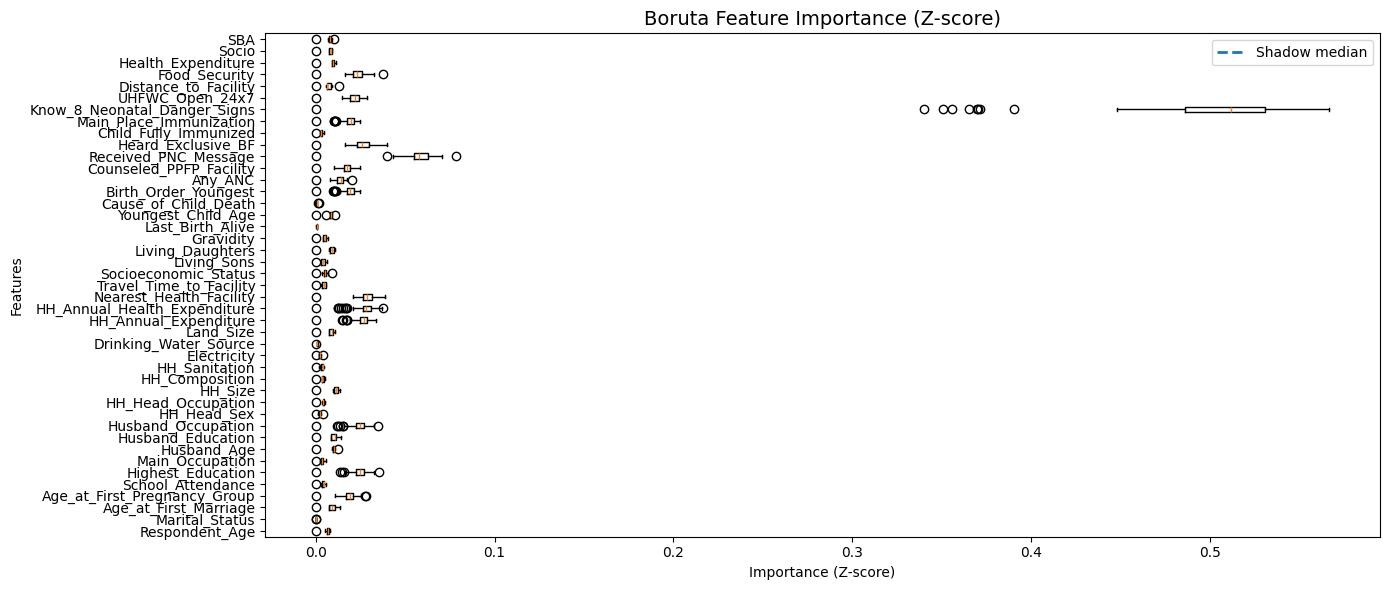

In [14]:
# -------------------------------
# Boruta Feature Importance Plot
# -------------------------------

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Convert Boruta importance history to DataFrame
imp_df = pd.DataFrame(
    boruta.importance_history_,
    columns=X_train_imp.columns
)

# Separate real and shadow features
shadow_features = [c for c in imp_df.columns if "shadow" in c.lower()]
real_features = [c for c in imp_df.columns if c not in shadow_features]

# Median shadow importance (Boruta threshold)
shadow_median = np.nanmedian(imp_df[shadow_features].values)

# Plot Boruta boxplots (default style)
plt.figure(figsize=(14, 6))
plt.boxplot(
    [imp_df[f].dropna() for f in real_features],
    labels=real_features,
    vert=False
)

plt.axvline(
    shadow_median,
    linestyle="--",
    linewidth=2,
    label="Shadow median"
)

plt.title("Boruta Feature Importance (Z-score)", fontsize=14)
plt.xlabel("Importance (Z-score)")
plt.ylabel("Features")
plt.legend()
plt.tight_layout()
plt.show()


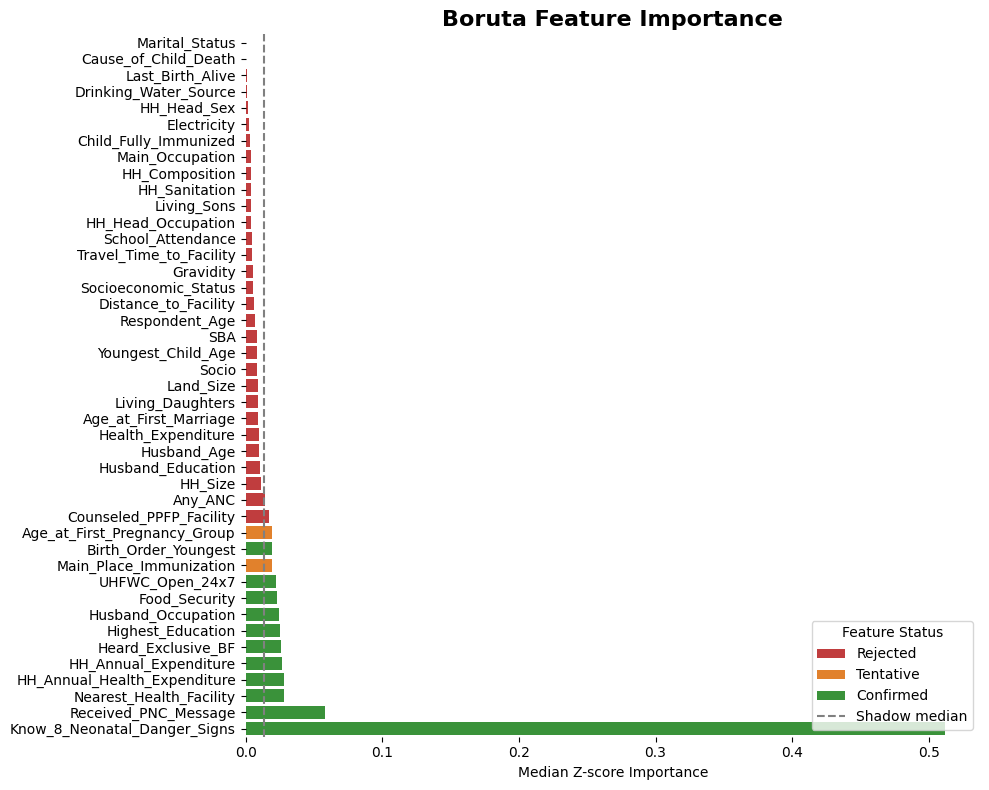

In [15]:
# -------------------------------
# Publication-quality Boruta Plot
# -------------------------------

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Extract Boruta importance statistics
imp_df = pd.DataFrame(boruta.importance_history_, columns=X_train_imp.columns)

# Identify feature status
feature_status = pd.Series(
    np.where(boruta.support_, "Confirmed",
             np.where(boruta.support_weak_, "Tentative", "Rejected")),
    index=X_train_imp.columns
)

# Compute median importance per feature
median_imp = imp_df.median().sort_values(ascending=True)

# Create plotting DataFrame
plot_df = pd.DataFrame({
    "Feature": median_imp.index,
    "Median_Z": median_imp.values,
    "Status": feature_status[median_imp.index].values
})

# Set color palette
palette = {"Confirmed": "#2ca02c", "Tentative": "#ff7f0e", "Rejected": "#d62728"}

# Plot
plt.figure(figsize=(10, 8))
sns.barplot(
    x="Median_Z",
    y="Feature",
    data=plot_df,
    hue="Status",
    dodge=False,
    palette=palette
)

# Style
plt.axvline(np.nanmedian(imp_df.iloc[:, ~boruta.support_].values), linestyle="--", color="grey", label="Shadow median")
plt.xlabel("Median Z-score Importance")
plt.ylabel("")
plt.title("Boruta Feature Importance", fontsize=16, weight="bold")
plt.legend(title="Feature Status", loc="lower right")
sns.despine(left=True, bottom=True)
plt.tight_layout()
plt.show()


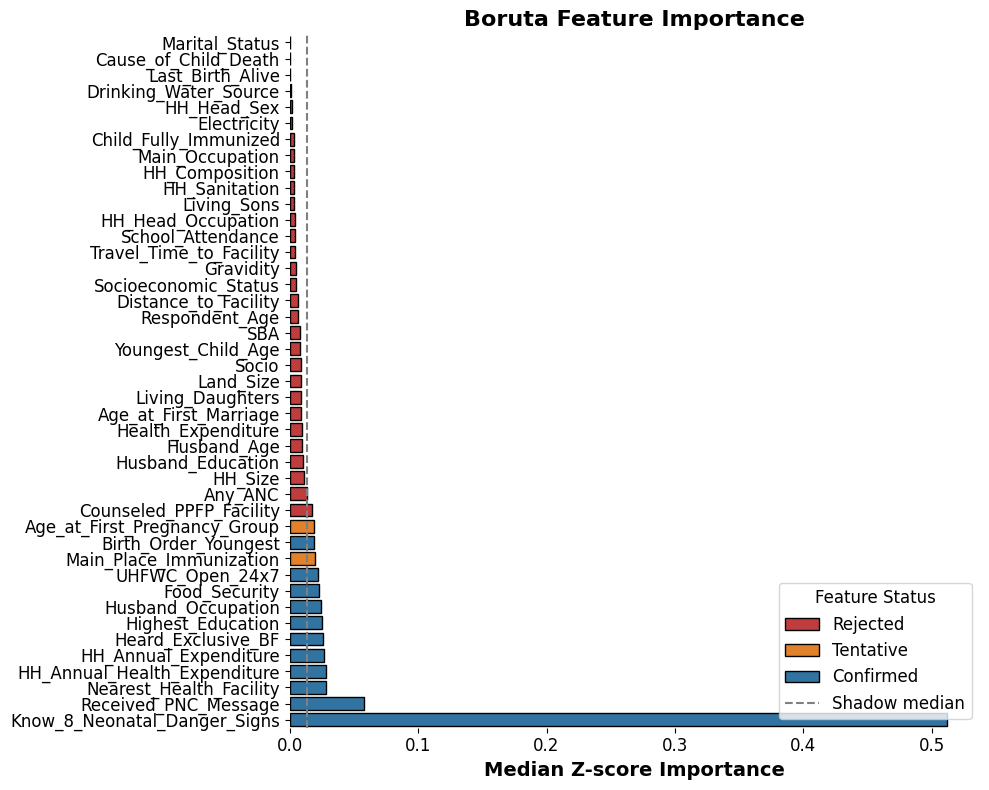

Figure saved at: /kaggle/working/figures/Boruta_Feature_Importance.tiff


In [16]:
# -------------------------------
# Publication-quality Boruta Plot for Journal (TIFF) - Kaggle-safe
# -------------------------------

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Create output folder if it doesn't exist
output_dir = "/kaggle/working/figures"
os.makedirs(output_dir, exist_ok=True)
tiff_path = os.path.join(output_dir, "Boruta_Feature_Importance.tiff")

# Extract Boruta importance statistics
imp_df = pd.DataFrame(boruta.importance_history_, columns=X_train_imp.columns)

# Identify feature status
feature_status = pd.Series(
    np.where(boruta.support_, "Confirmed",
             np.where(boruta.support_weak_, "Tentative", "Rejected")),
    index=X_train_imp.columns
)

# Compute median importance per feature and sort
median_imp = imp_df.median().sort_values(ascending=True)

# Prepare plotting DataFrame
plot_df = pd.DataFrame({
    "Feature": median_imp.index,
    "Median_Z": median_imp.values,
    "Status": feature_status[median_imp.index].values
})

# Color palette - bright & clean
palette = {"Confirmed": "#1f77b4", "Tentative": "#ff7f0e", "Rejected": "#d62728"}

# Initialize figure
plt.figure(figsize=(10, 8))
sns.barplot(
    x="Median_Z",
    y="Feature",
    data=plot_df,
    hue="Status",
    dodge=False,
    palette=palette,
    edgecolor="black"
)

# Dashed line = median of shadow features
shadow_median = np.nanmedian(imp_df.iloc[:, ~boruta.support_].values)
plt.axvline(shadow_median, linestyle="--", color="grey", linewidth=1.5, label="Shadow median")

# Style for journal-ready look
plt.xlabel("Median Z-score Importance", fontsize=14, weight="bold")
plt.ylabel("")
plt.title("Boruta Feature Importance", fontsize=16, weight="bold")
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.legend(title="Feature Status", fontsize=12, title_fontsize=12, loc="lower right")
sns.despine(left=True, bottom=True)

# Save as high-resolution TIFF in Kaggle working folder
plt.tight_layout()
plt.savefig(tiff_path, format='tiff', dpi=600)
plt.show()

print(f"Figure saved at: {tiff_path}")


In [17]:
# Model define
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier

# External ML libs (available in Kaggle)
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000, class_weight="balanced"
    ),

    "ANN": MLPClassifier(
        hidden_layer_sizes=(50, 25),
        max_iter=1000,
        random_state=123
    ),

    "KNN": KNeighborsClassifier(n_neighbors=5),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=5,
        class_weight="balanced",
        random_state=123
    ),

    "RVM (SVM-RBF)": SVC(
        kernel="rbf",
        probability=True,
        class_weight="balanced",
        random_state=123
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        class_weight="balanced",
        random_state=123
    ),

    "AdaBoost": AdaBoostClassifier(
        n_estimators=200,
        random_state=123
    ),

    "XGBoost": XGBClassifier(
        n_estimators=300,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        eval_metric="logloss",
        random_state=123
    ),

    "LightGBM": LGBMClassifier(
        n_estimators=300,
        learning_rate=0.05,
        class_weight="balanced",
        random_state=123
    ),

    "CatBoost": CatBoostClassifier(
        iterations=300,
        learning_rate=0.05,
        depth=6,
        verbose=0,
        random_state=123
    )
}


/usr/local/lib/python3.12/dist-packages/sqlalchemy/orm/query.py:195: SyntaxWarning: "is not" with 'tuple' literal. Did you mean "!="?
  if entities is not ():


In [18]:
# Train
from sklearn.metrics import (
    accuracy_score, f1_score, recall_score,
    roc_auc_score, confusion_matrix
)

results = []

for name, model in models.items():
    model.fit(X_train_sel, y_train)

    y_pred = model.predict(X_test_sel)
    y_prob = model.predict_proba(X_test_sel)[:, 1]

    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "F1 Score": f1_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "Sensitivity": tp / (tp + fn),
        "Specificity": tn / (tn + fp),
        "AUROC": roc_auc_score(y_test, y_prob)
    })


[LightGBM] [Info] Number of positive: 341, number of negative: 301
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.001098 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 56
[LightGBM] [Info] Number of data points in the train set: 642, number of used features: 11
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=-0.000000
[LightGBM] [Info] Start training from score -0.000000
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


In [19]:
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="AUROC", ascending=False
).round(3)

results_df


,Model,Accuracy,F1 Score,Recall,Sensitivity,Specificity,AUROC
6,AdaBoost,0.870,0.873,0.847,0.847,0.895,0.906
0,Logistic Regression,0.870,0.873,0.847,0.847,0.895,0.901
7,XGBoost,0.857,0.864,0.859,0.859,0.855,0.894
4,RVM (SVM-RBF),0.870,0.873,0.847,0.847,0.895,0.891
9,CatBoost,0.832,0.838,0.824,0.824,0.842,0.889
5,Random Forest,0.845,0.854,0.859,0.859,0.829,0.886
2,KNN,0.845,0.852,0.847,0.847,0.842,0.882
8,LightGBM,0.839,0.849,0.859,0.859,0.816,0.879
3,Decision Tree,0.820,0.828,0.824,0.824,0.816,0.864
1,ANN,0.776,0.793,0.812,0.812,0.737,0.857


In [20]:
# Round all numeric columns to 2 decimal places
results_df_rounded = results_df.copy()
numeric_cols = results_df_rounded.select_dtypes(include=['float', 'int']).columns
results_df_rounded[numeric_cols] = results_df_rounded[numeric_cols].round(2)

# Save to CSV
results_df_rounded.to_csv("ML_model_performance.csv", index=False)

# Optional: display
results_df_rounded


,Model,Accuracy,F1 Score,Recall,Sensitivity,Specificity,AUROC
6,AdaBoost,0.870,0.870,0.850,0.850,0.900,0.910
0,Logistic Regression,0.870,0.870,0.850,0.850,0.900,0.900
7,XGBoost,0.860,0.860,0.860,0.860,0.860,0.890
4,RVM (SVM-RBF),0.870,0.870,0.850,0.850,0.900,0.890
9,CatBoost,0.830,0.840,0.820,0.820,0.840,0.890
5,Random Forest,0.840,0.850,0.860,0.860,0.830,0.890
2,KNN,0.840,0.850,0.850,0.850,0.840,0.880
8,LightGBM,0.840,0.850,0.860,0.860,0.820,0.880
3,Decision Tree,0.820,0.830,0.820,0.820,0.820,0.860
1,ANN,0.780,0.790,0.810,0.810,0.740,0.860


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


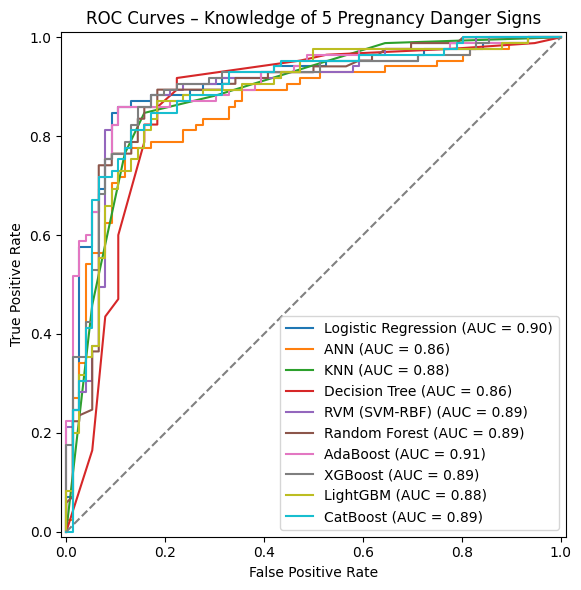

In [21]:
## Visualization
from sklearn.metrics import RocCurveDisplay
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

for name, model in models.items():
    # Only models with predict_proba
    if hasattr(model, "predict_proba"):
        RocCurveDisplay.from_estimator(
            model,
            X_test_sel,
            y_test,
            name=name,
            ax=plt.gca()
        )

plt.plot([0, 1], [0, 1], linestyle="--", color="gray")
plt.title("ROC Curves – Knowledge of 5 Pregnancy Danger Signs")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


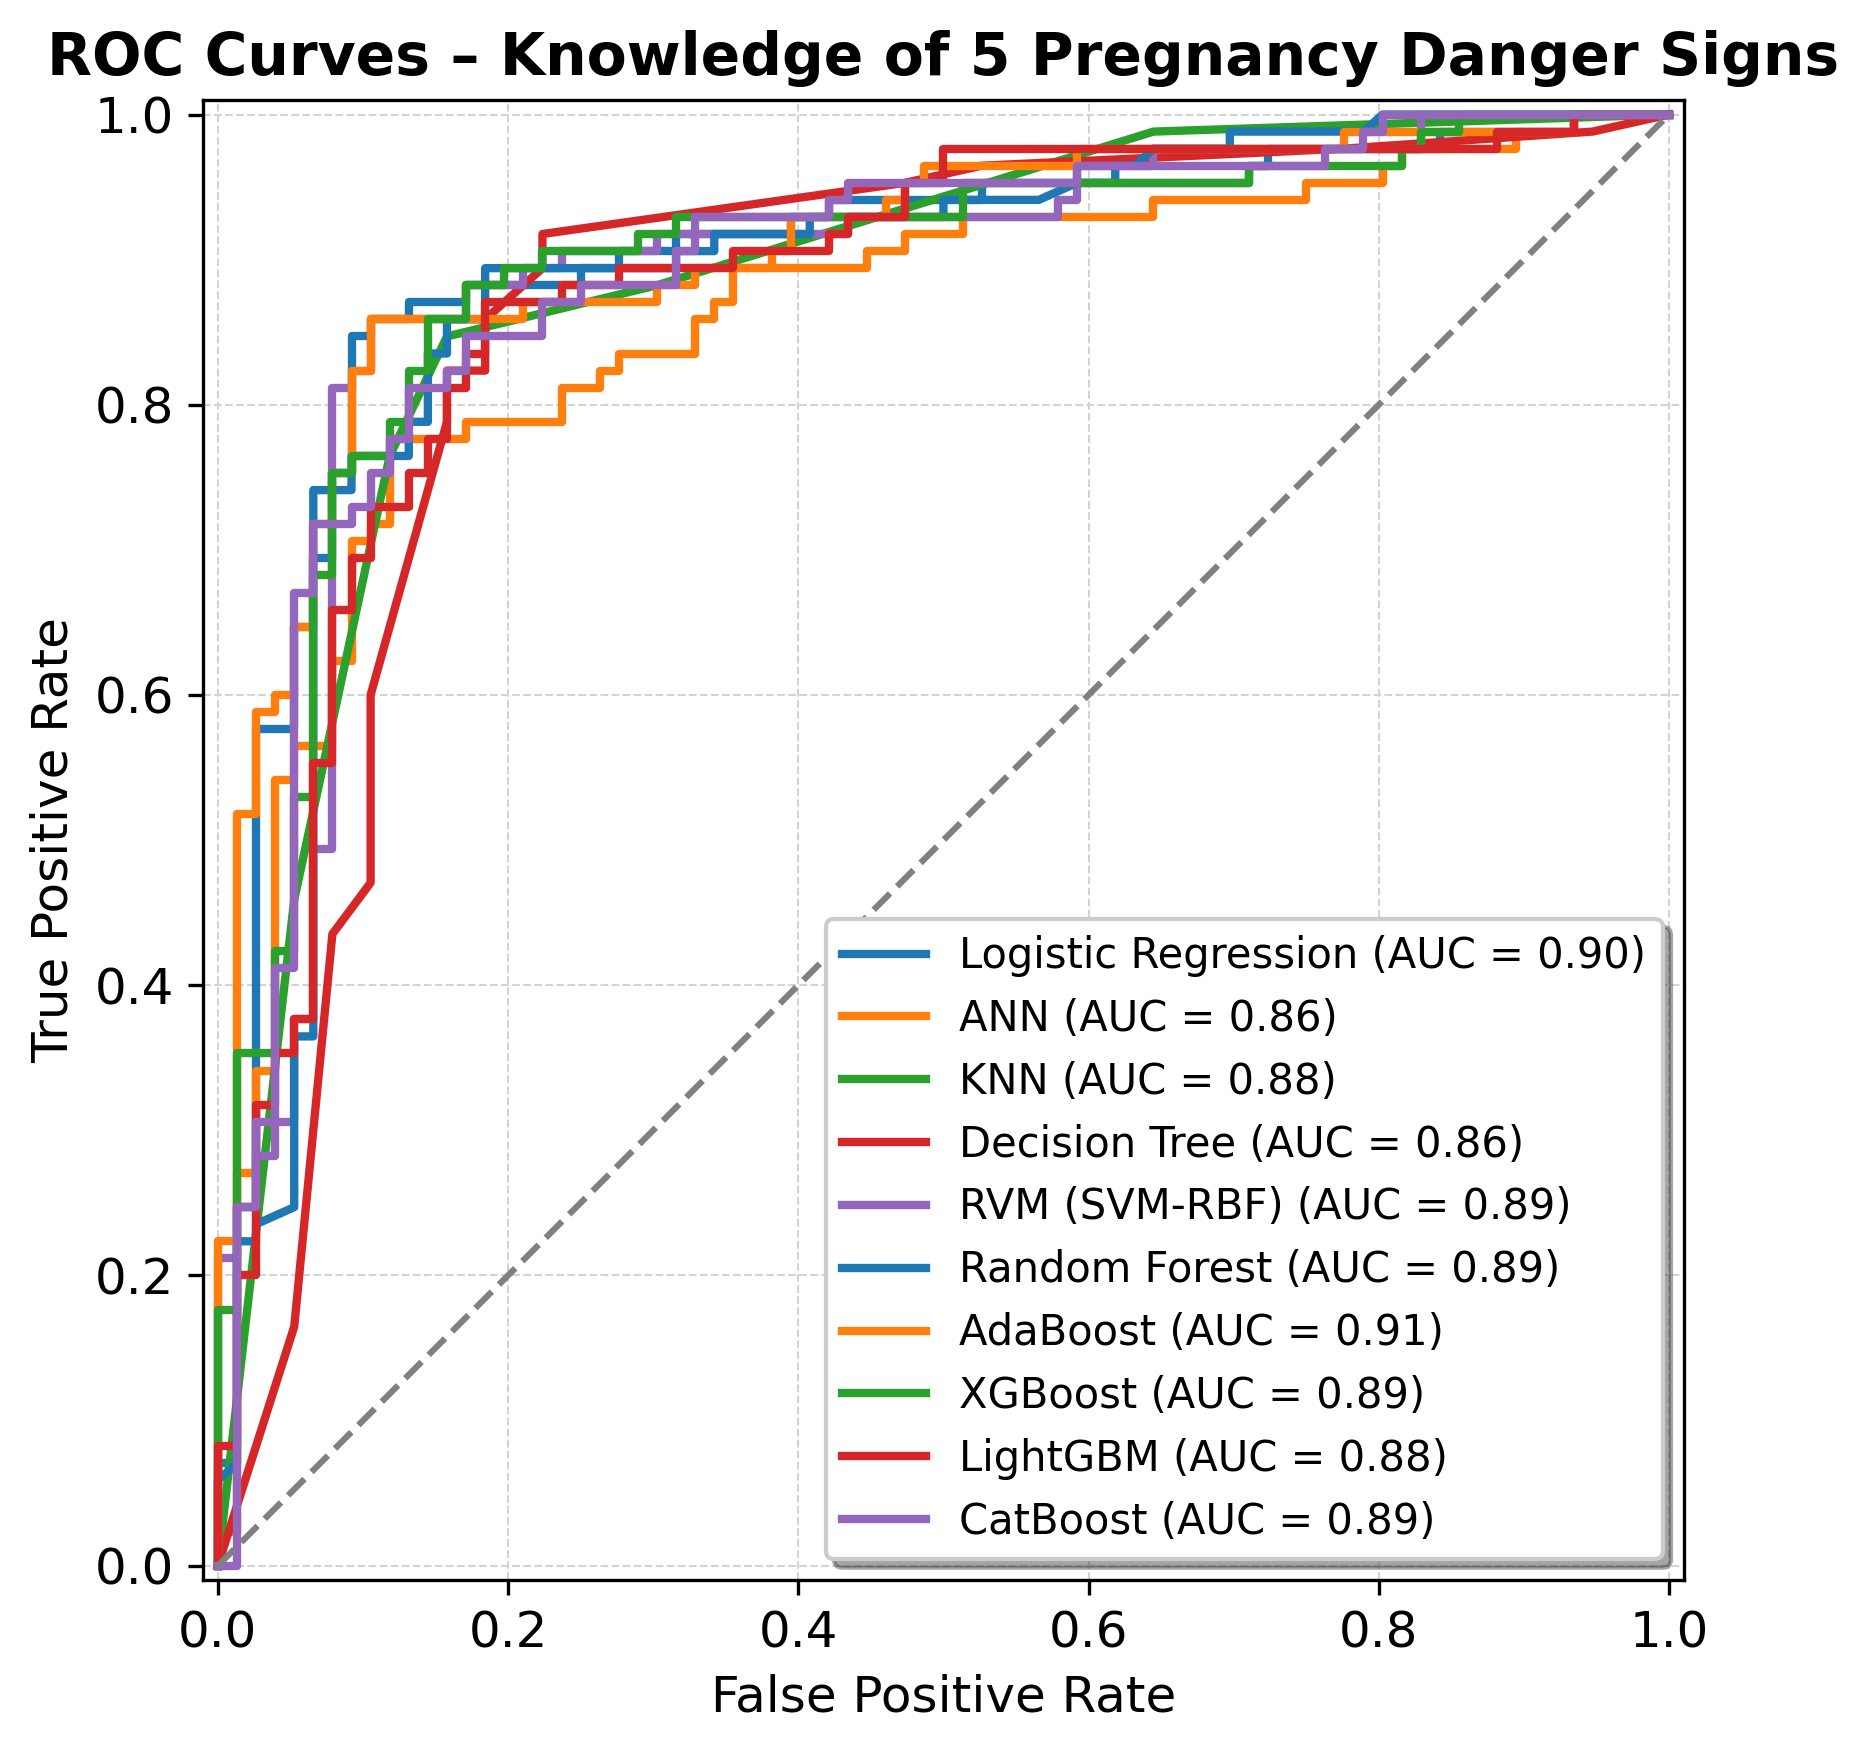

In [23]:
## Visualization – IEEE journal style, polished & save as TIFF
from sklearn.metrics import RocCurveDisplay
import matplotlib.pyplot as plt

# High-resolution figure for journal submission
plt.figure(figsize=(8, 6), dpi=300)

# Use a clean white background with light grid
plt.rcParams.update({
    "axes.facecolor": "white",
    "axes.edgecolor": "black",
    "axes.grid": True,
    "grid.color": "lightgray",
    "grid.linestyle": "--",
    "grid.linewidth": 0.5,
    "font.size": 12,
    "lines.linewidth": 2
})

colors = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red', 'tab:purple']
ax = plt.gca()

for idx, (name, model) in enumerate(models.items()):
    if hasattr(model, "predict_proba"):
        RocCurveDisplay.from_estimator(
            model,
            X_test_sel,
            y_test,
            name=name,
            ax=ax,
            color=colors[idx % len(colors)]
        )

# Diagonal reference line
plt.plot([0, 1], [0, 1], linestyle="--", color="gray", linewidth=1.5)

# Titles and labels – IEEE style
plt.title("ROC Curves – Knowledge of 5 Pregnancy Danger Signs", fontsize=14, fontweight='bold')
plt.xlabel("False Positive Rate", fontsize=12)
plt.ylabel("True Positive Rate", fontsize=12)

# Legend
plt.legend(loc="lower right", fontsize=10, frameon=True, shadow=True)

plt.tight_layout()

# Save figure as TIFF – high quality for journal submission
plt.savefig("ROC_Curves_Pregnancy_Danger.tiff", format='tiff', dpi=300)

plt.show()


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


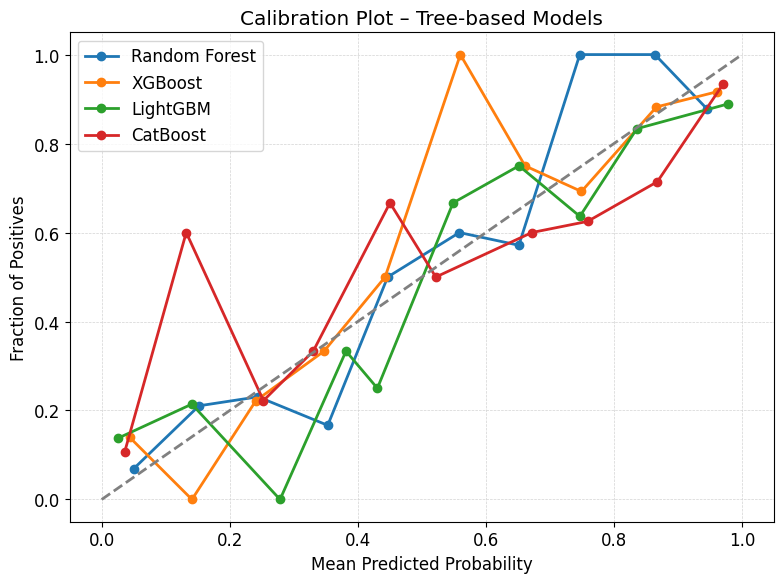

In [24]:
from sklearn.calibration import calibration_curve

plt.figure(figsize=(8, 6))

tree_models = ["Random Forest", "XGBoost", "LightGBM", "CatBoost"]

for name in tree_models:
    model = models[name]
    y_prob = model.predict_proba(X_test_sel)[:, 1]
    prob_true, prob_pred = calibration_curve(y_test, y_prob, n_bins=10)

    plt.plot(prob_pred, prob_true, marker='o', label=name)

plt.plot([0, 1], [0, 1], linestyle='--', color='gray')
plt.xlabel("Mean Predicted Probability")
plt.ylabel("Fraction of Positives")
plt.title("Calibration Plot – Tree-based Models")
plt.legend()
plt.tight_layout()
plt.show()


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


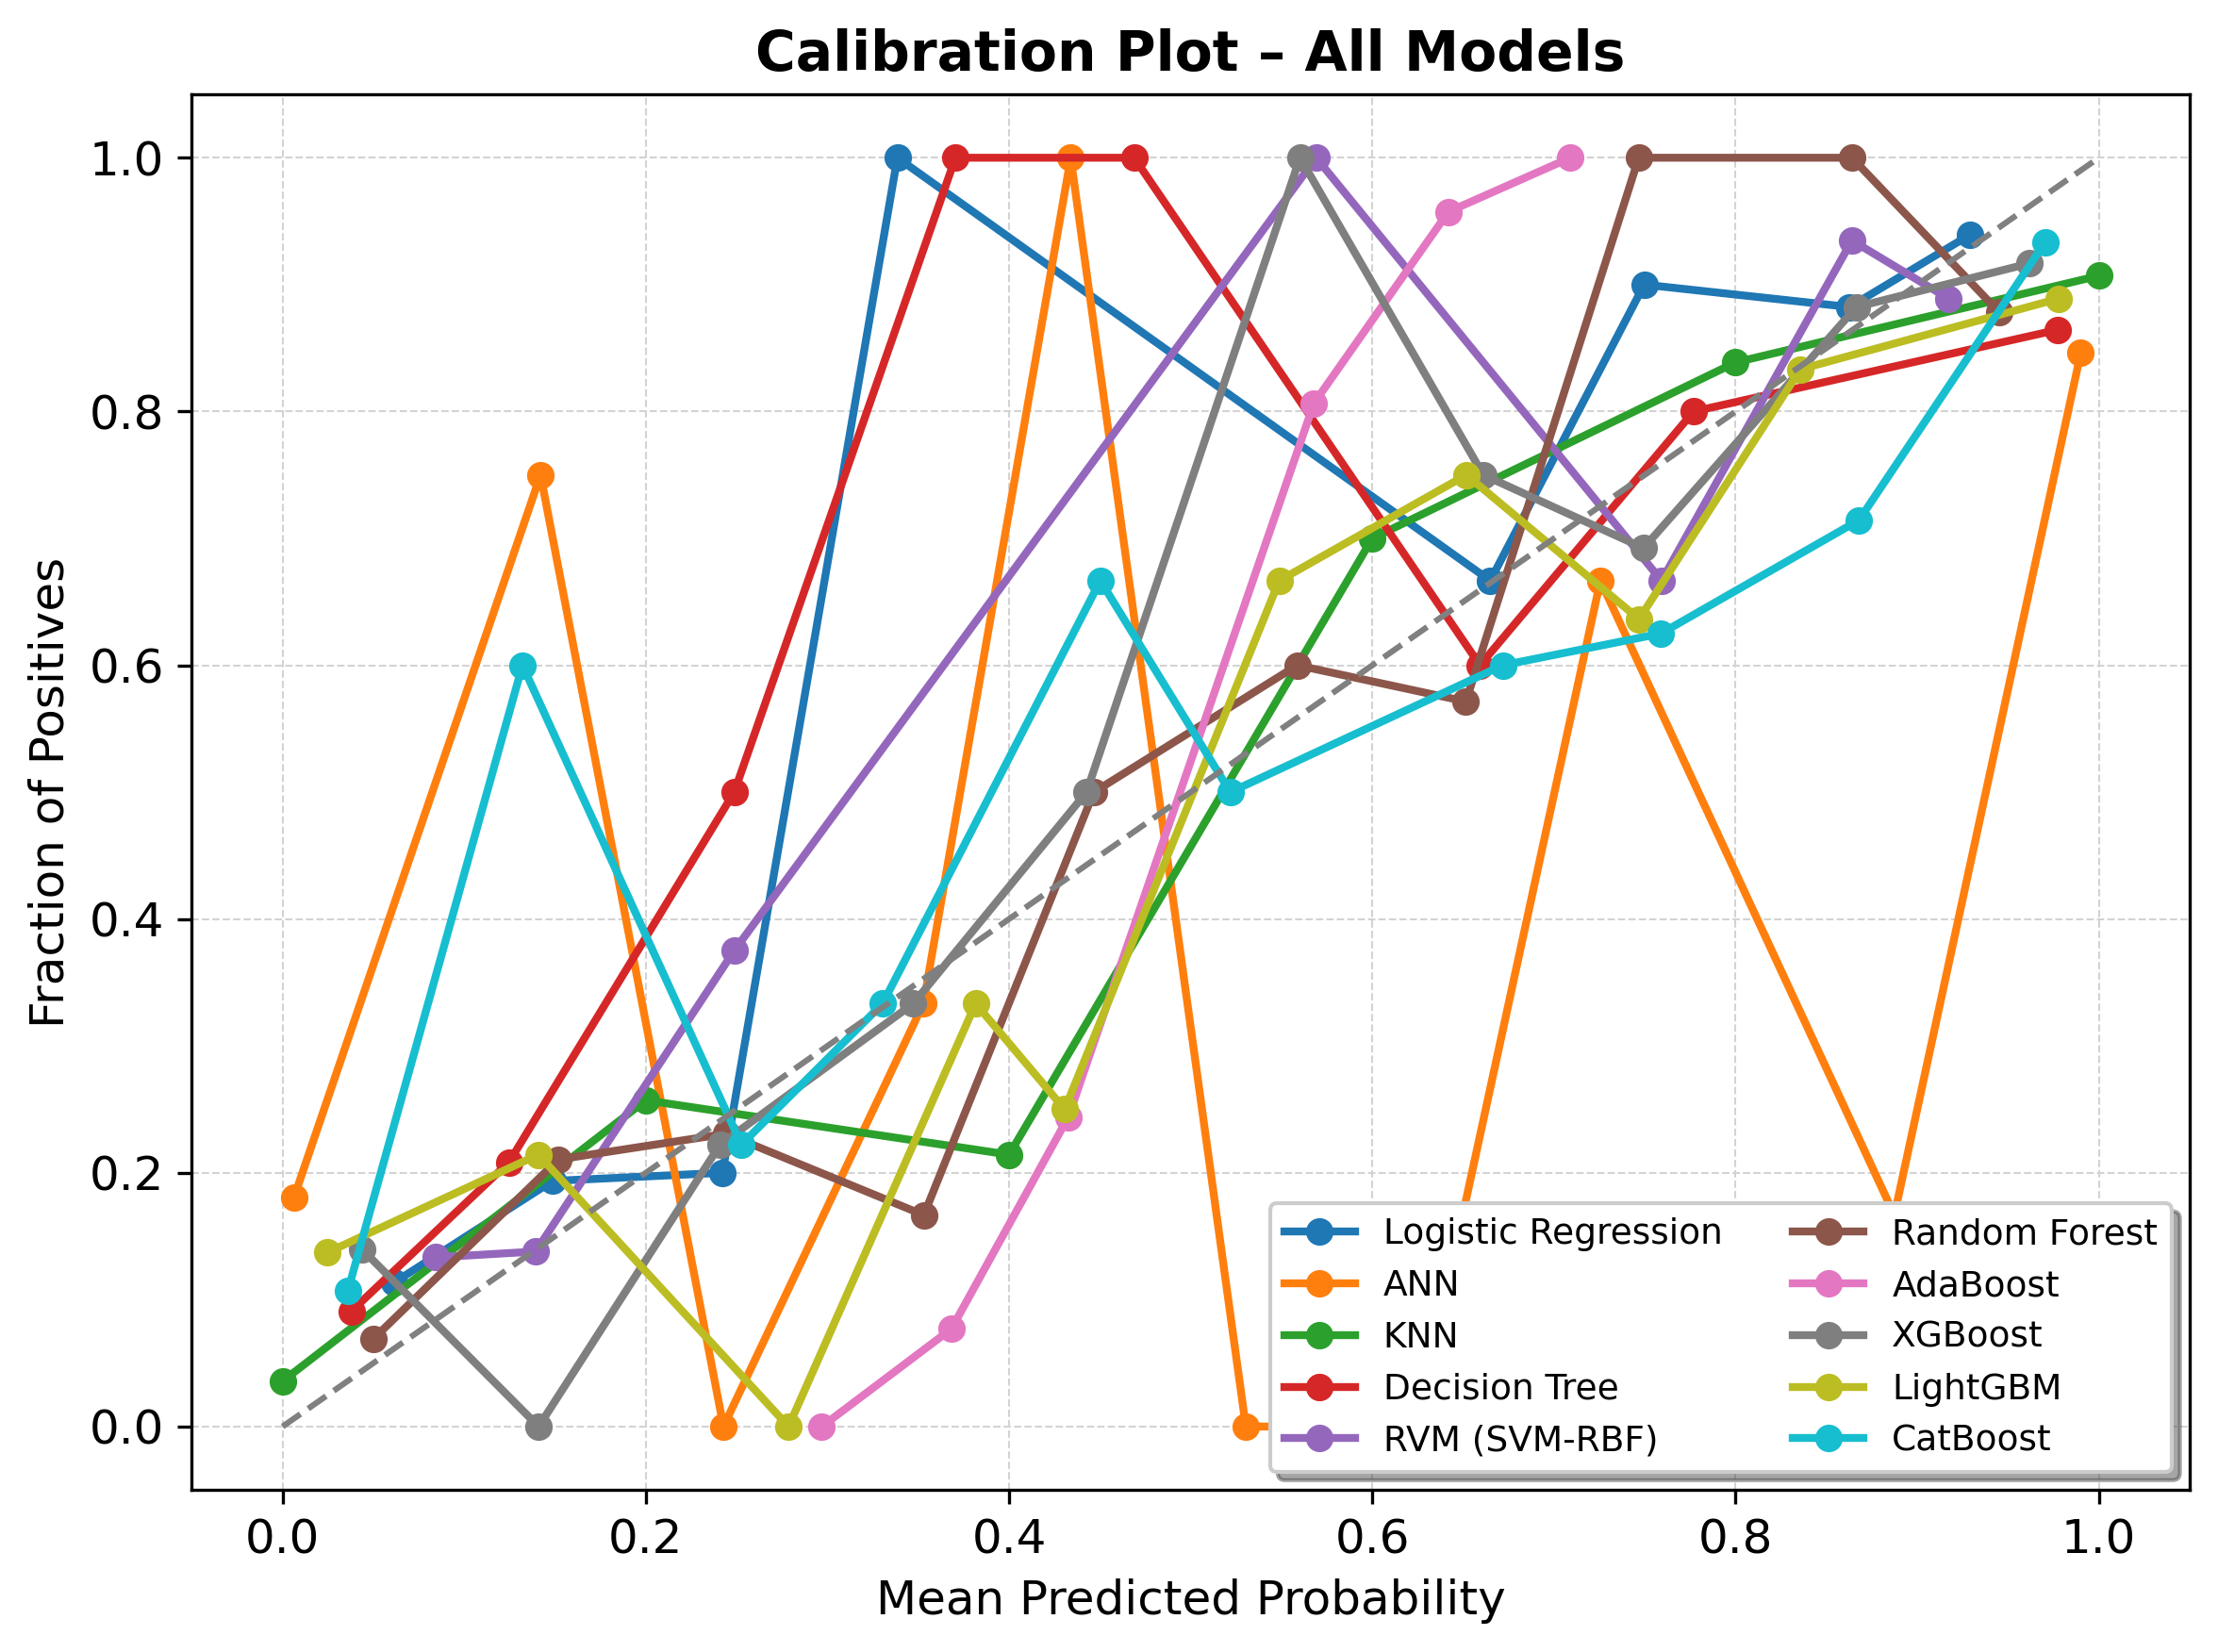

In [26]:
from sklearn.calibration import calibration_curve
import matplotlib.pyplot as plt

# High-resolution figure for journal submission
plt.figure(figsize=(8, 6), dpi=300)

# Clean white background with light grid
plt.rcParams.update({
    "axes.facecolor": "white",
    "axes.edgecolor": "black",
    "axes.grid": True,
    "grid.color": "lightgray",
    "grid.linestyle": "--",
    "grid.linewidth": 0.5,
    "font.size": 12,
    "lines.linewidth": 2
})

# Define all 10 models
all_models = list(models.keys())  # automatically take all models from your models dict

# Define distinct colors (extend if more than 10)
colors = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red', 'tab:purple',
          'tab:brown', 'tab:pink', 'tab:gray', 'tab:olive', 'tab:cyan']

for idx, name in enumerate(all_models):
    model = models[name]
    
    # Only plot if model has predict_proba
    if hasattr(model, "predict_proba"):
        y_prob = model.predict_proba(X_test_sel)[:, 1]
        prob_true, prob_pred = calibration_curve(y_test, y_prob, n_bins=10)
        
        plt.plot(prob_pred, prob_true, marker='o',
                 color=colors[idx % len(colors)],
                 label=name,
                 linewidth=2)

# Diagonal reference line (perfect calibration)
plt.plot([0, 1], [0, 1], linestyle='--', color='gray', linewidth=1.5)

# Titles and labels – IEEE style
plt.title("Calibration Plot – All Models", fontsize=14, fontweight='bold')
plt.xlabel("Mean Predicted Probability", fontsize=12)
plt.ylabel("Fraction of Positives", fontsize=12)

# Legend
plt.legend(loc="lower right", fontsize=9, frameon=True, shadow=True, ncol=2)  # 2 columns for clarity

plt.tight_layout()

# Save figure as TIFF – high quality for journal submission
plt.savefig("Calibration_Plot_All_Models.tiff", format='tiff', dpi=300)

plt.show()


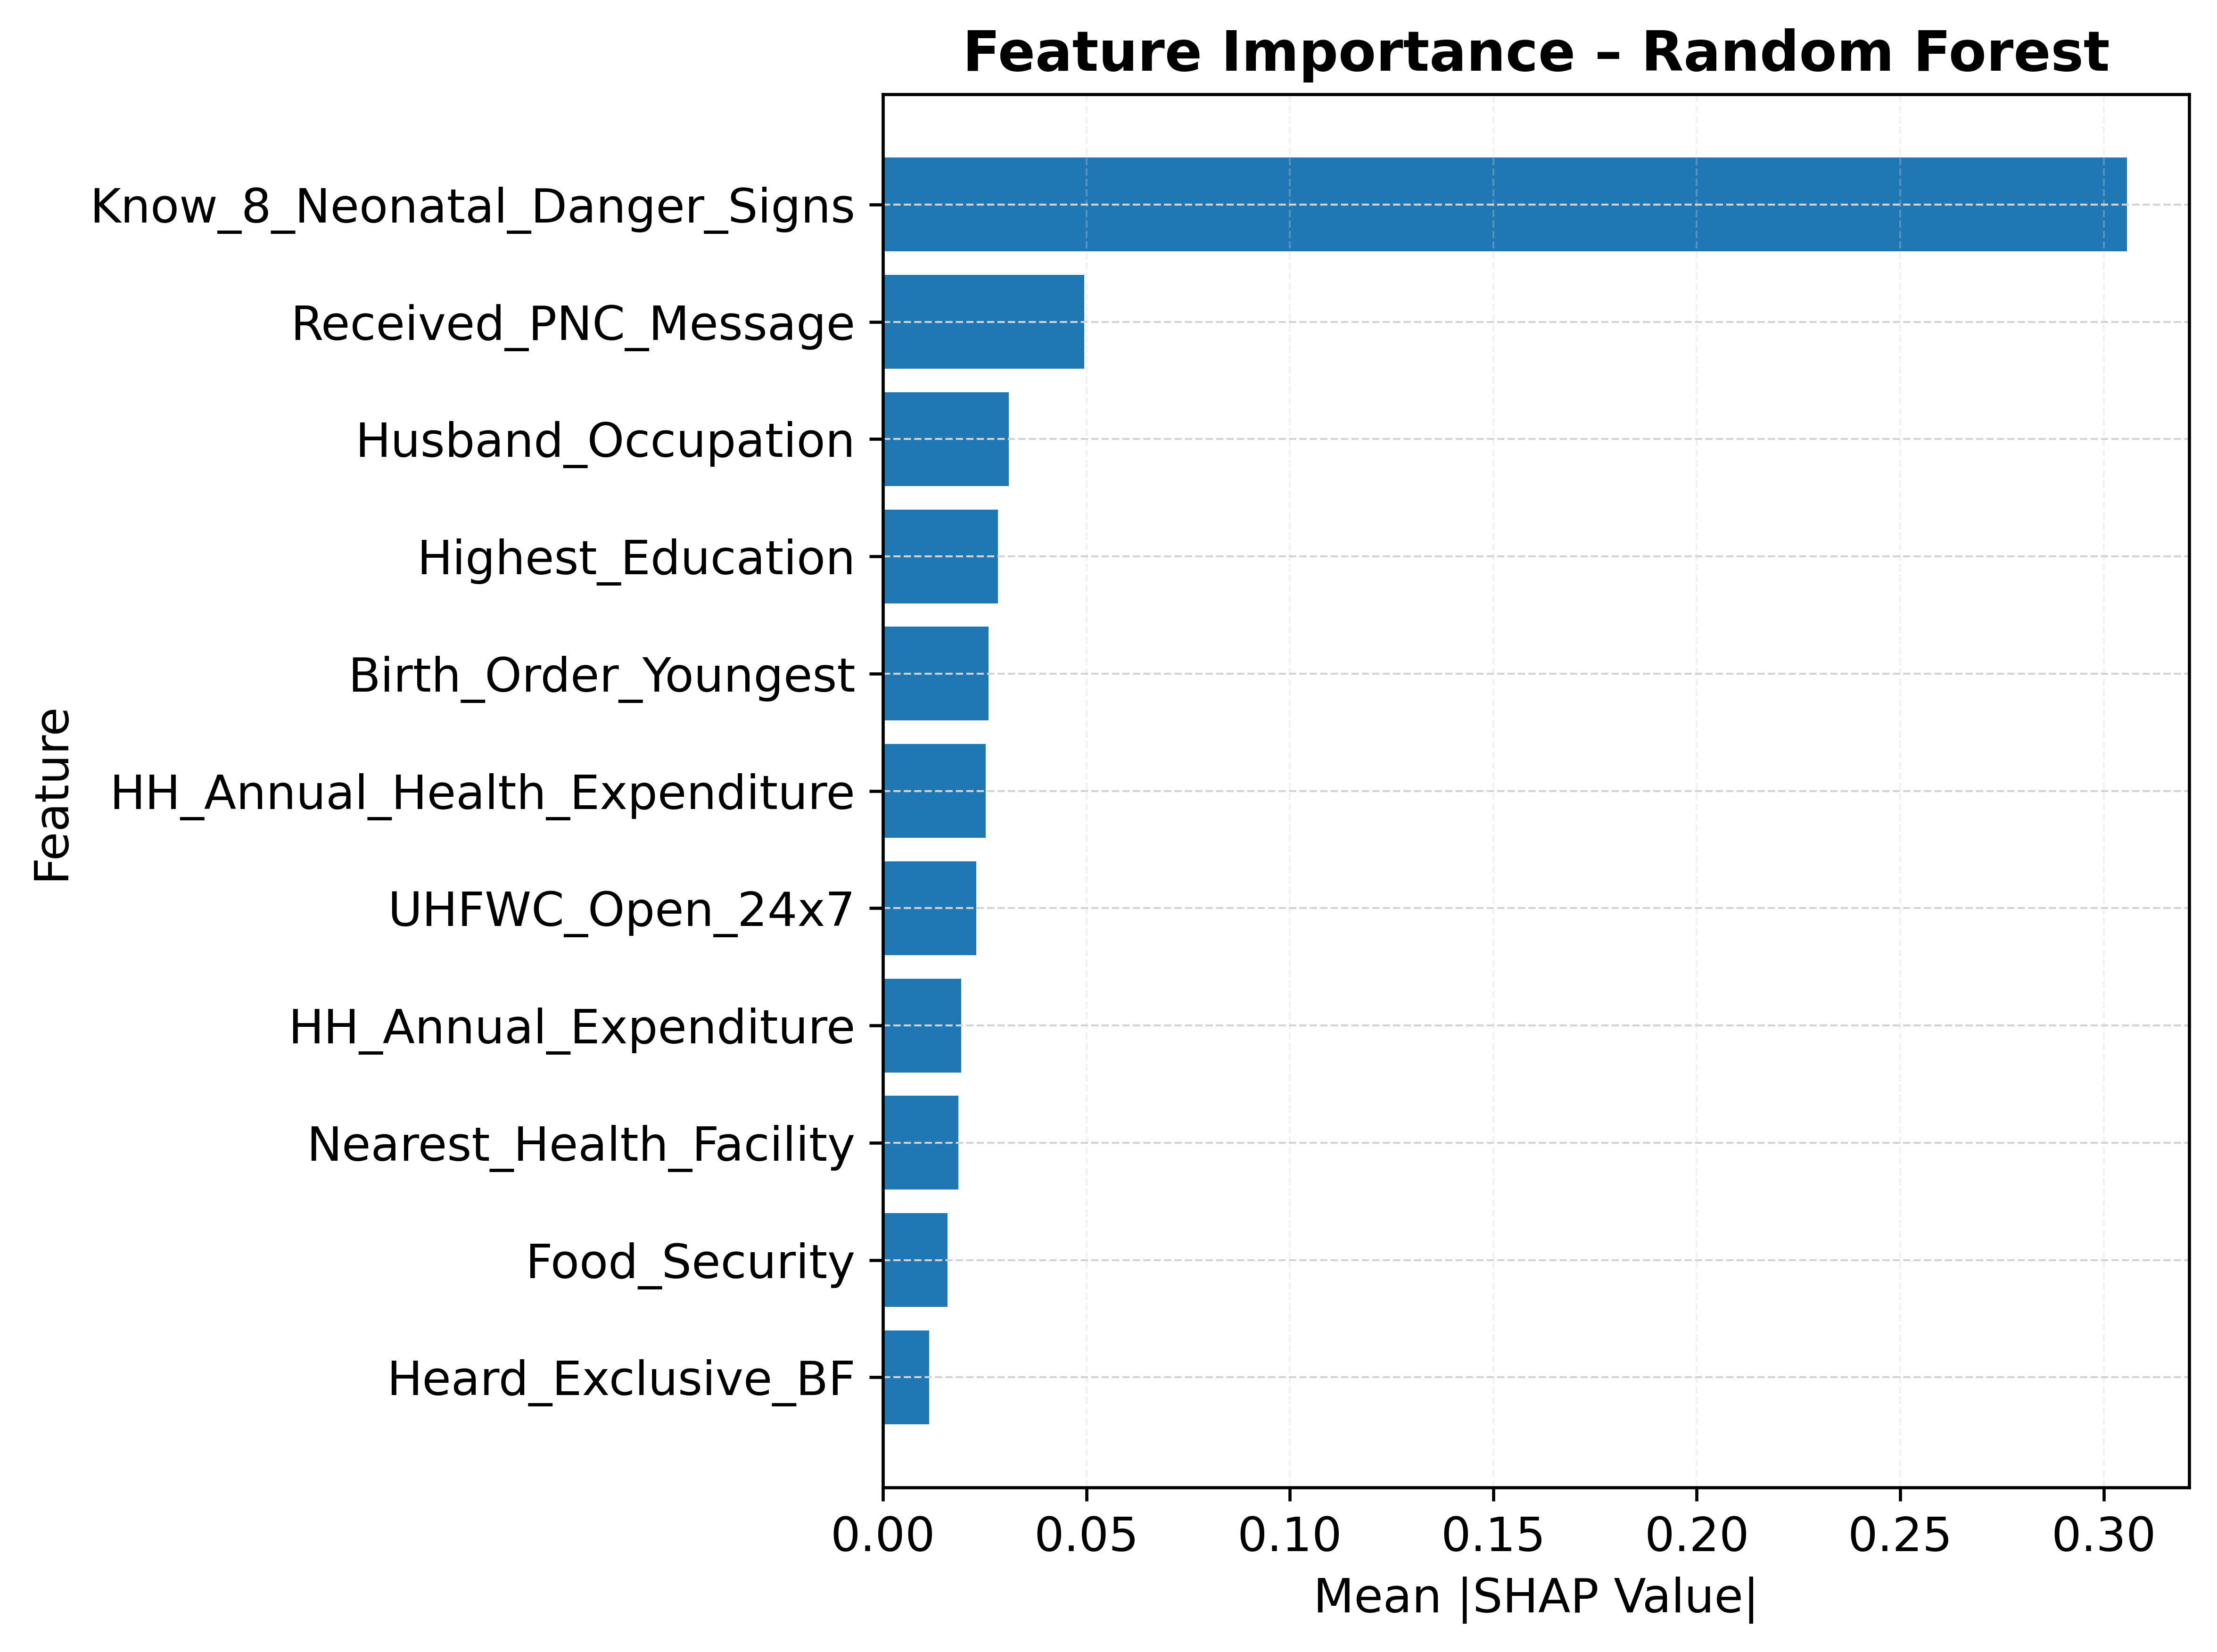

In [35]:
import shap
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# Convert selected features to DataFrame
X_test_sel_df = pd.DataFrame(X_test_sel, columns=selected_features)
X_train_sel_df = pd.DataFrame(X_train_sel, columns=selected_features)

# Random Forest SHAP
rf_model = models["Random Forest"]
explainer_rf = shap.TreeExplainer(rf_model)
shap_values_rf = explainer_rf(X_test_sel_df)

# For binary classification, class 1
if isinstance(shap_values_rf, list):
    shap_values_class1 = shap_values_rf[1]
else:
    shap_values_class1 = shap_values_rf.values[:, :, 1] if shap_values_rf.values.ndim == 3 else shap_values_rf.values

# Compute mean absolute SHAP values (feature importance)
shap_importance = np.abs(shap_values_class1).mean(axis=0)
importance_df = pd.DataFrame({
    'Feature': X_test_sel_df.columns,
    'Importance': shap_importance
}).sort_values(by='Importance', ascending=True)

# Plot clean bar chart
plt.figure(figsize=(8,6), dpi=600)
plt.barh(
    importance_df['Feature'],
    importance_df['Importance'],
    color="#1f77b4"
)
plt.xlabel("Mean |SHAP Value|", fontsize=12)
plt.ylabel("Feature", fontsize=12)
plt.title("Feature Importance – Random Forest", fontsize=14, fontweight='bold')
plt.grid(axis='x', alpha=0.3)
plt.gca().set_facecolor("white")  # clean white background
plt.tight_layout()

# Save as TIFF
plt.savefig("/kaggle/working/SHAP_RF_FeatureImportance.tiff", format="tiff")
plt.show()


In [30]:
import shap

# Create explainer
explainer_rf = shap.TreeExplainer(models['Random Forest'])

# Get SHAP values for X_test_sel
shap_values_rf = explainer_rf.shap_values(X_test_sel)

# Check type
print(type(shap_values_rf))  # should be list for binary class
print(len(shap_values_rf))   # should be 2

# Select positive class (class 1)
shap_values_pos = shap_values_rf[1]  # shape should be (161, 11)
print("SHAP values shape:", shap_values_pos.shape)


<class 'numpy.ndarray'>
161
SHAP values shape: (11, 2)


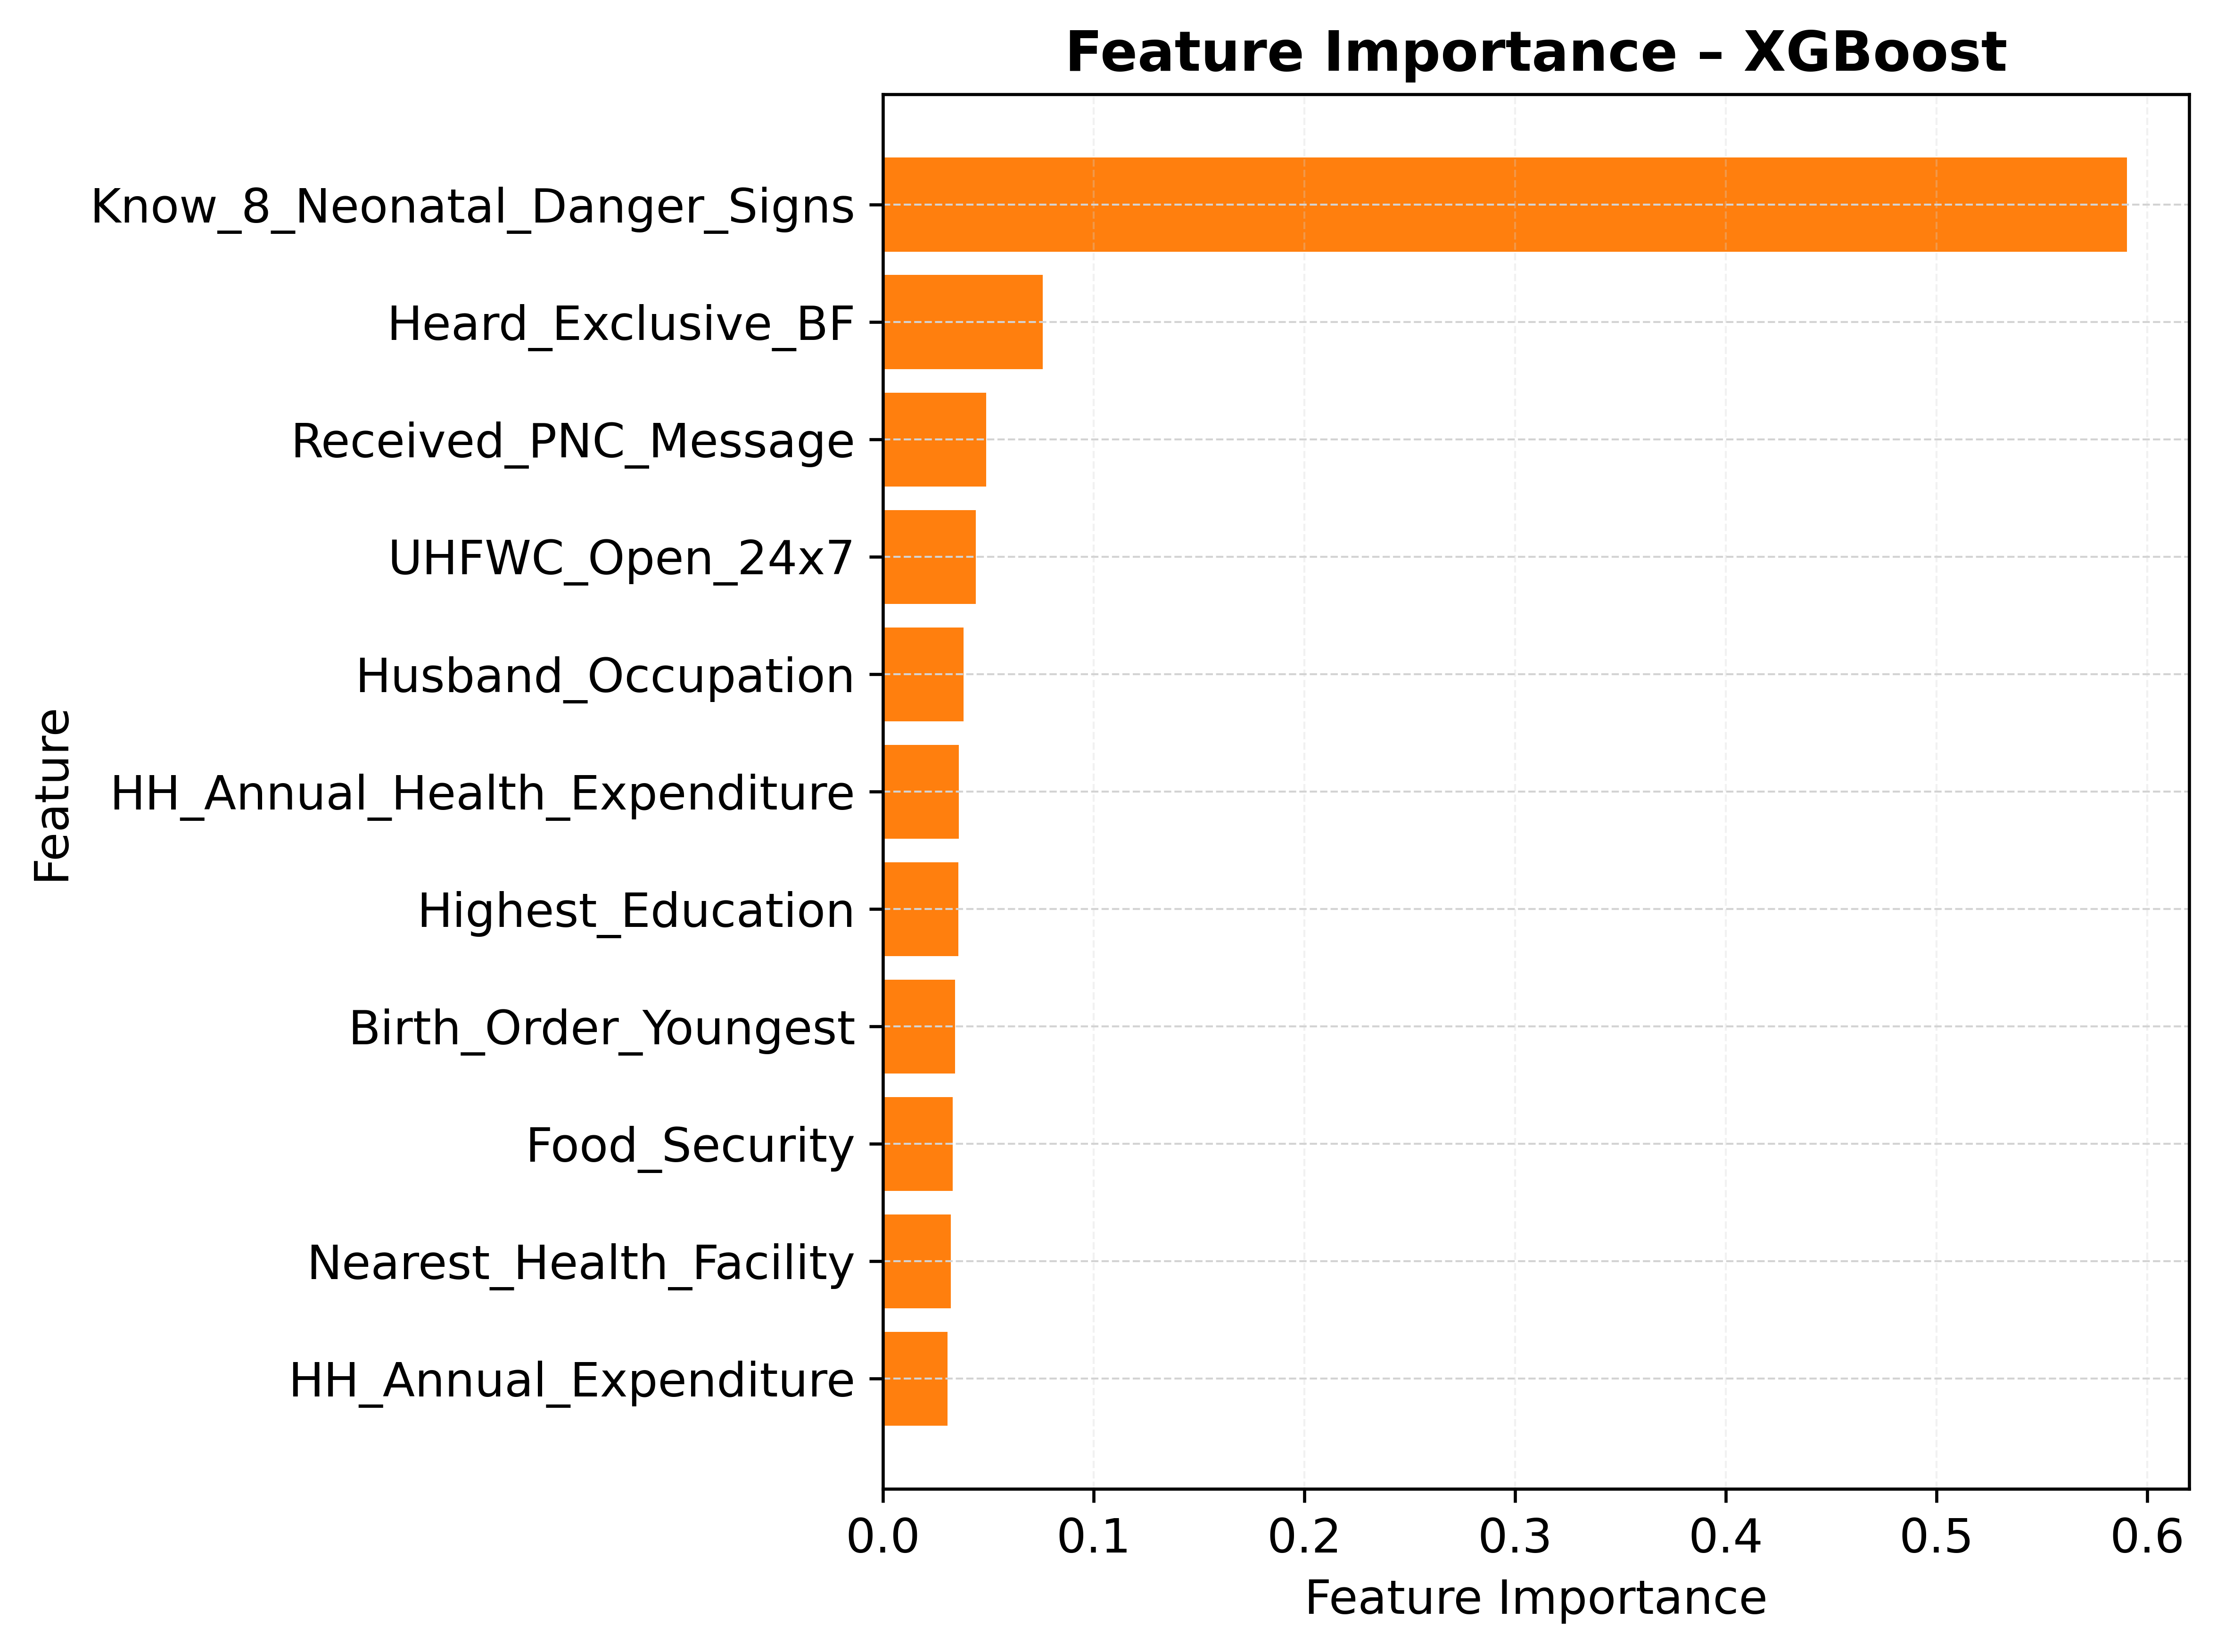

In [39]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# Convert selected features to DataFrame
X_test_sel_df = pd.DataFrame(X_test_sel, columns=selected_features)

# XGBoost model from sklearn API
xgb_model = models["XGBoost"]

# Get feature importances (gain-based)
importance_values = xgb_model.feature_importances_
importance_df = pd.DataFrame({
    'Feature': X_test_sel_df.columns,
    'Importance': importance_values
}).sort_values(by='Importance', ascending=True)

# Plot horizontal bar chart
plt.figure(figsize=(8,6), dpi=600)
plt.barh(
    importance_df['Feature'],
    importance_df['Importance'],
    color="#ff7f0e"  # bright orange
)
plt.xlabel("Feature Importance", fontsize=12)
plt.ylabel("Feature", fontsize=12)
plt.title("Feature Importance – XGBoost", fontsize=14, fontweight='bold')
plt.grid(axis='x', alpha=0.3)
plt.gca().set_facecolor("white")  # clean white background
plt.tight_layout()

# Save as TIFF
plt.savefig("/kaggle/working/XGBoost_FeatureImportance.tiff", format="tiff")
plt.show()


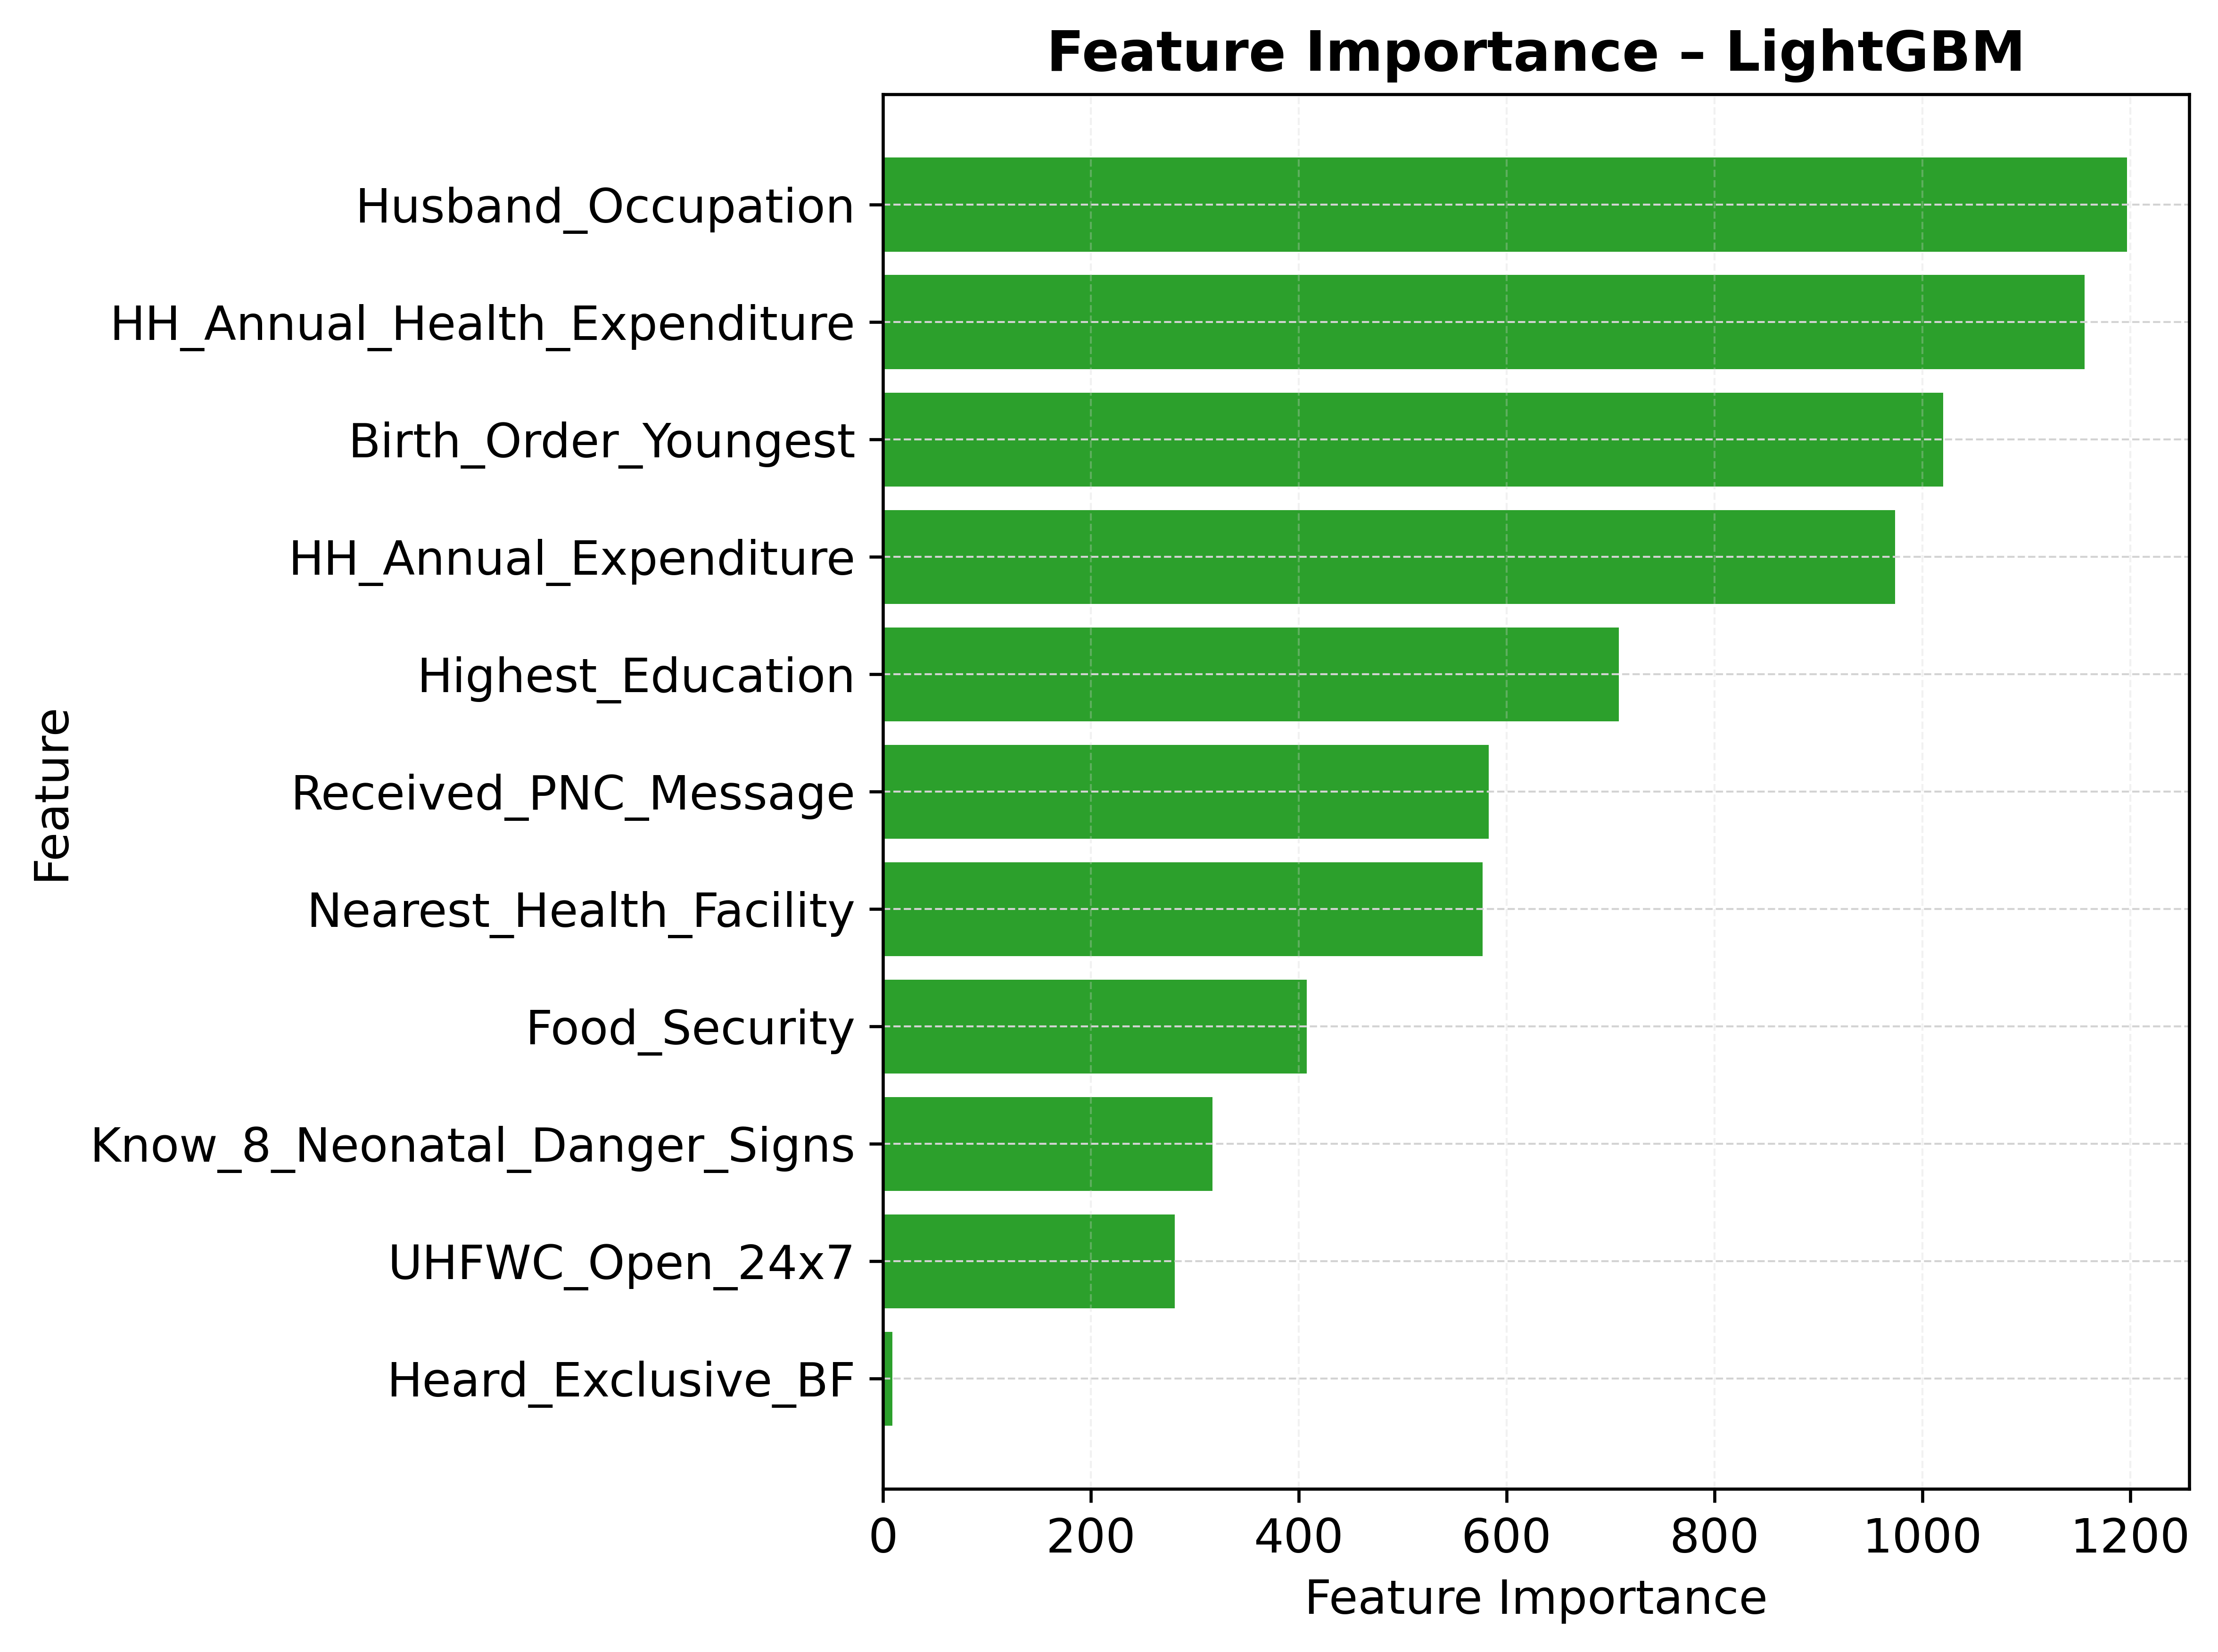

In [40]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# Convert selected features to DataFrame
X_test_sel_df = pd.DataFrame(X_test_sel, columns=selected_features)

# LightGBM model from sklearn API
lgb_model = models["LightGBM"]

# Get feature importances (gain-based)
importance_values = lgb_model.feature_importances_
importance_df = pd.DataFrame({
    'Feature': X_test_sel_df.columns,
    'Importance': importance_values
}).sort_values(by='Importance', ascending=True)

# Plot horizontal bar chart
plt.figure(figsize=(8,6), dpi=600)
plt.barh(
    importance_df['Feature'],
    importance_df['Importance'],
    color="#2ca02c"  # bright green
)
plt.xlabel("Feature Importance", fontsize=12)
plt.ylabel("Feature", fontsize=12)
plt.title("Feature Importance – LightGBM", fontsize=14, fontweight='bold')
plt.grid(axis='x', alpha=0.3)
plt.gca().set_facecolor("white")  # clean white background
plt.tight_layout()

# Save as TIFF
plt.savefig("/kaggle/working/LGBM_FeatureImportance.tiff", format="tiff")
plt.show()


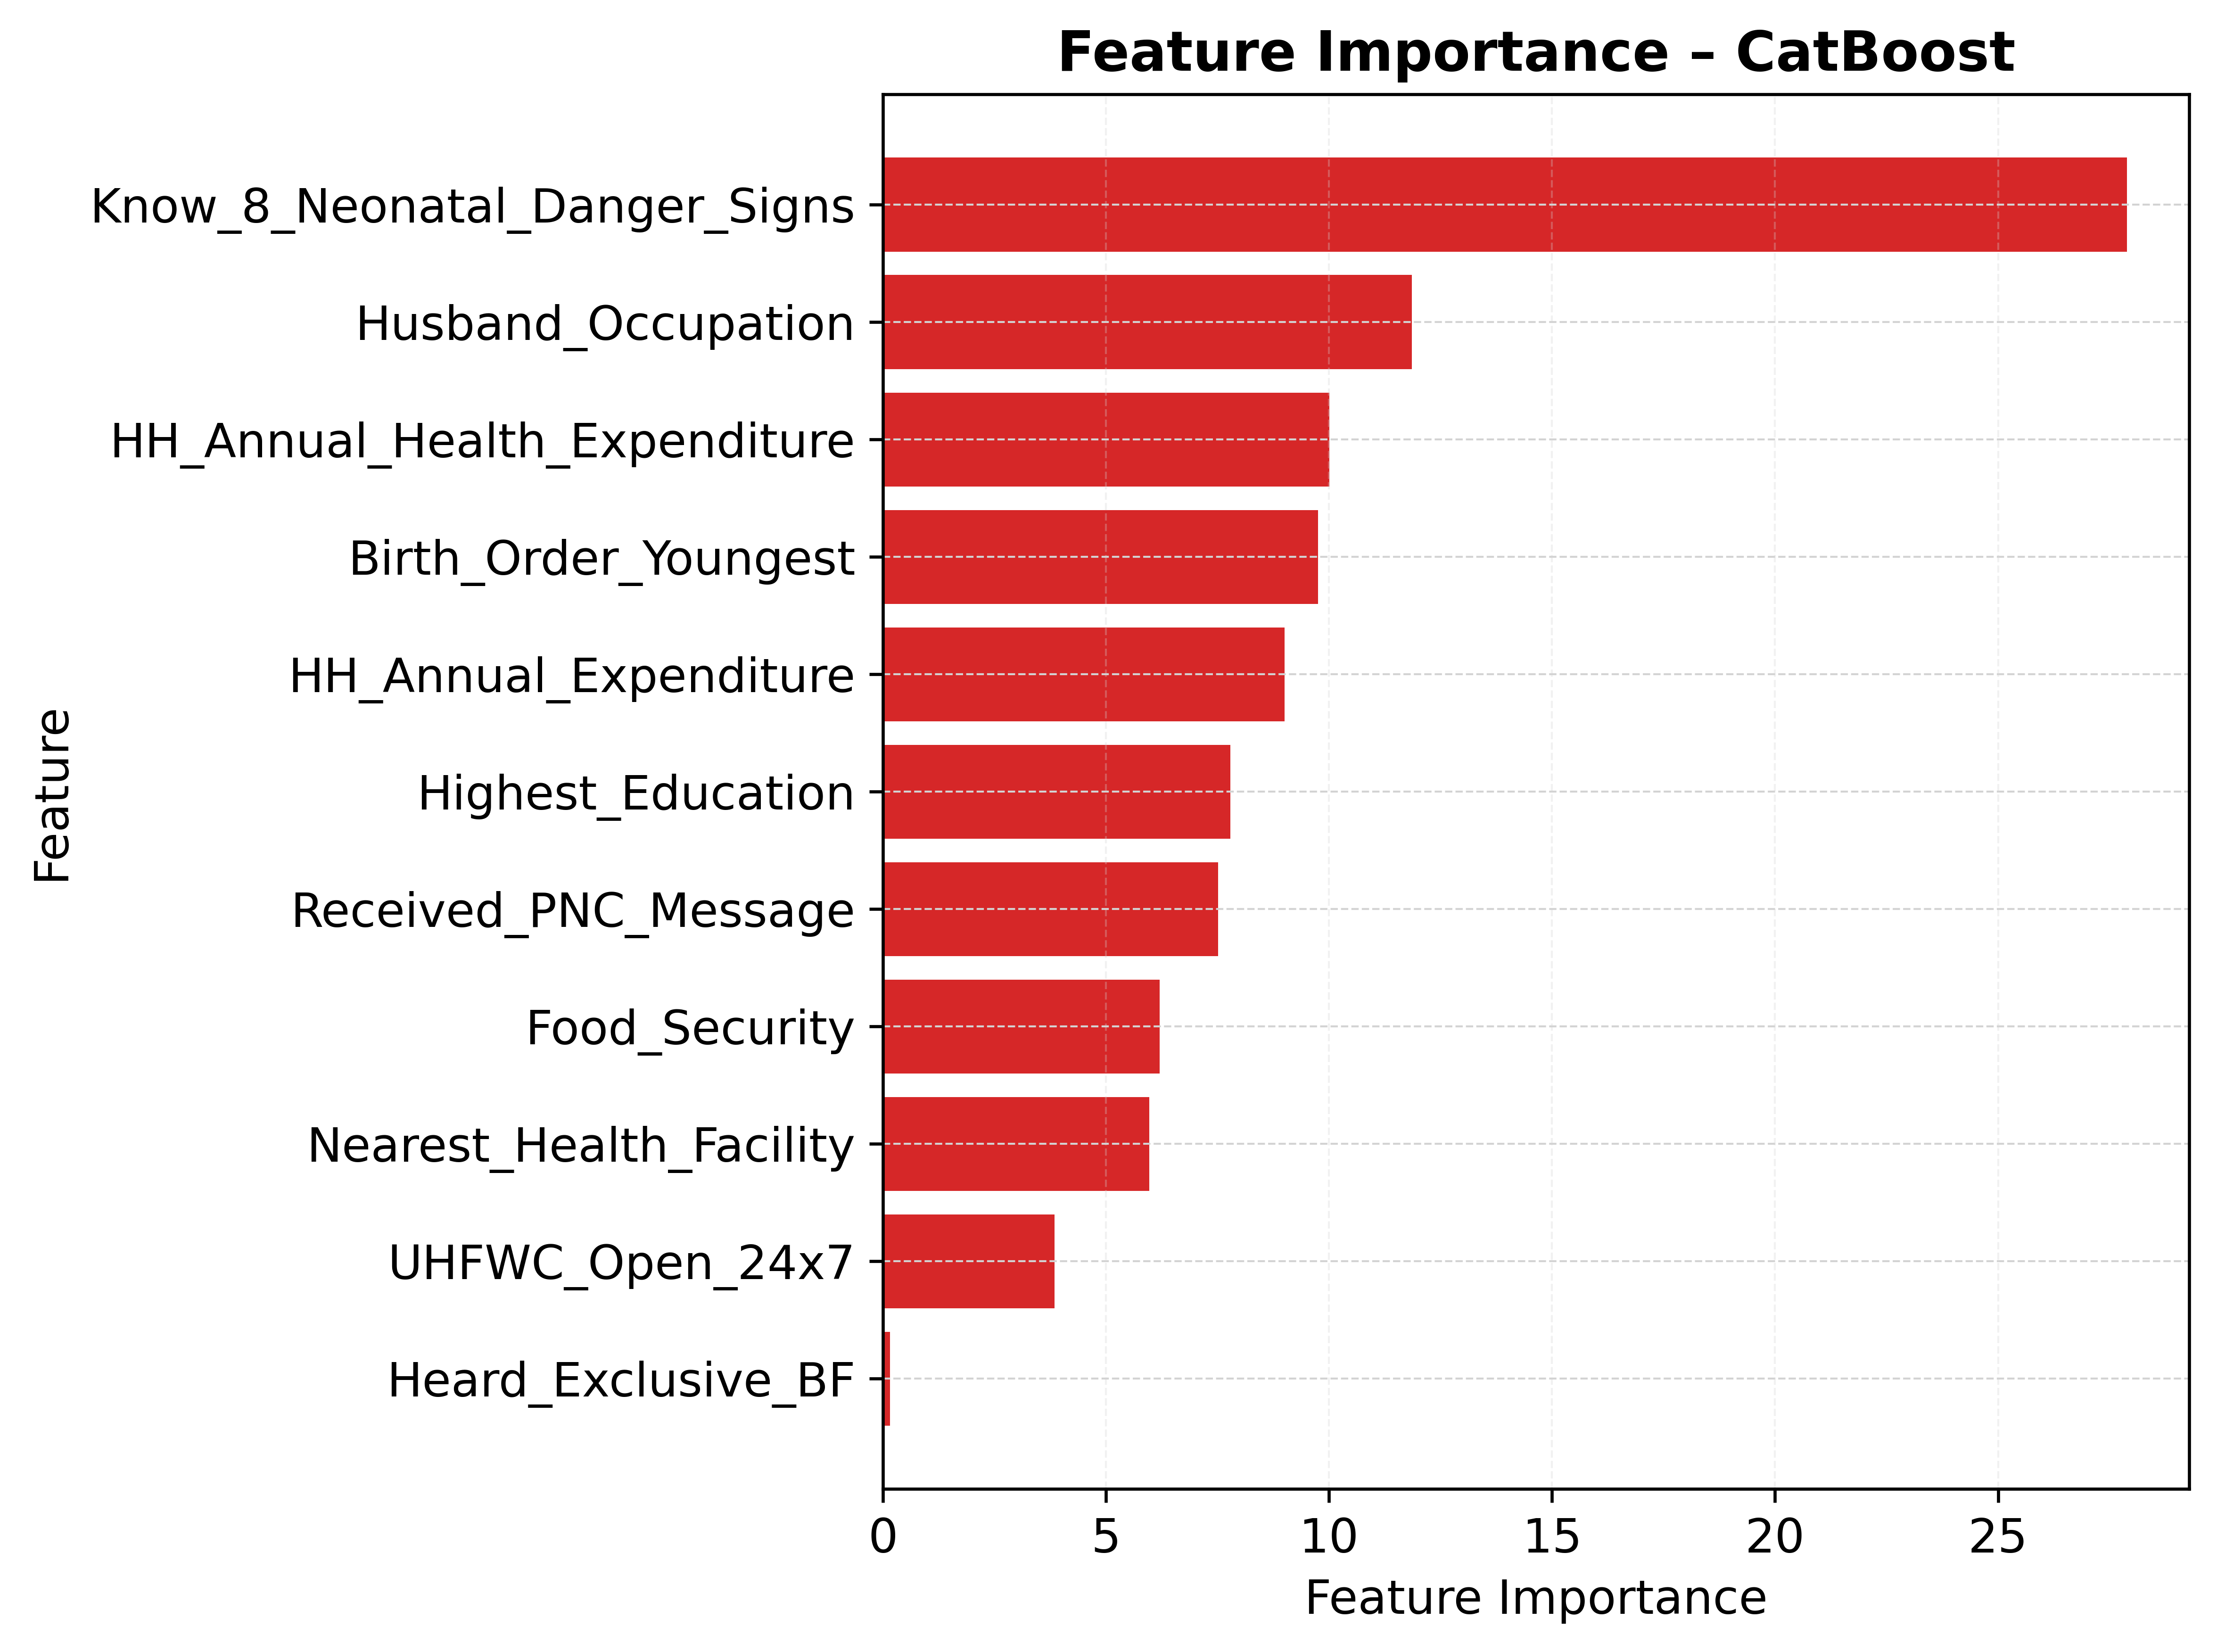

In [41]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# Convert selected features to DataFrame
X_test_sel_df = pd.DataFrame(X_test_sel, columns=selected_features)

# CatBoost model from sklearn API
cat_model = models["CatBoost"]

# Get feature importances (use 'PredictionValuesChange' for best effect)
importance_values = cat_model.get_feature_importance(type='PredictionValuesChange')
importance_df = pd.DataFrame({
    'Feature': X_test_sel_df.columns,
    'Importance': importance_values
}).sort_values(by='Importance', ascending=True)

# Plot horizontal bar chart
plt.figure(figsize=(8,6), dpi=600)
plt.barh(
    importance_df['Feature'],
    importance_df['Importance'],
    color="#d62728"  # bright red
)
plt.xlabel("Feature Importance", fontsize=12)
plt.ylabel("Feature", fontsize=12)
plt.title("Feature Importance – CatBoost", fontsize=14, fontweight='bold')
plt.grid(axis='x', alpha=0.3)
plt.gca().set_facecolor("white")  # clean white background
plt.tight_layout()

# Save as TIFF
plt.savefig("/kaggle/working/CatBoost_FeatureImportance.tiff", format="tiff")
plt.show()



/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


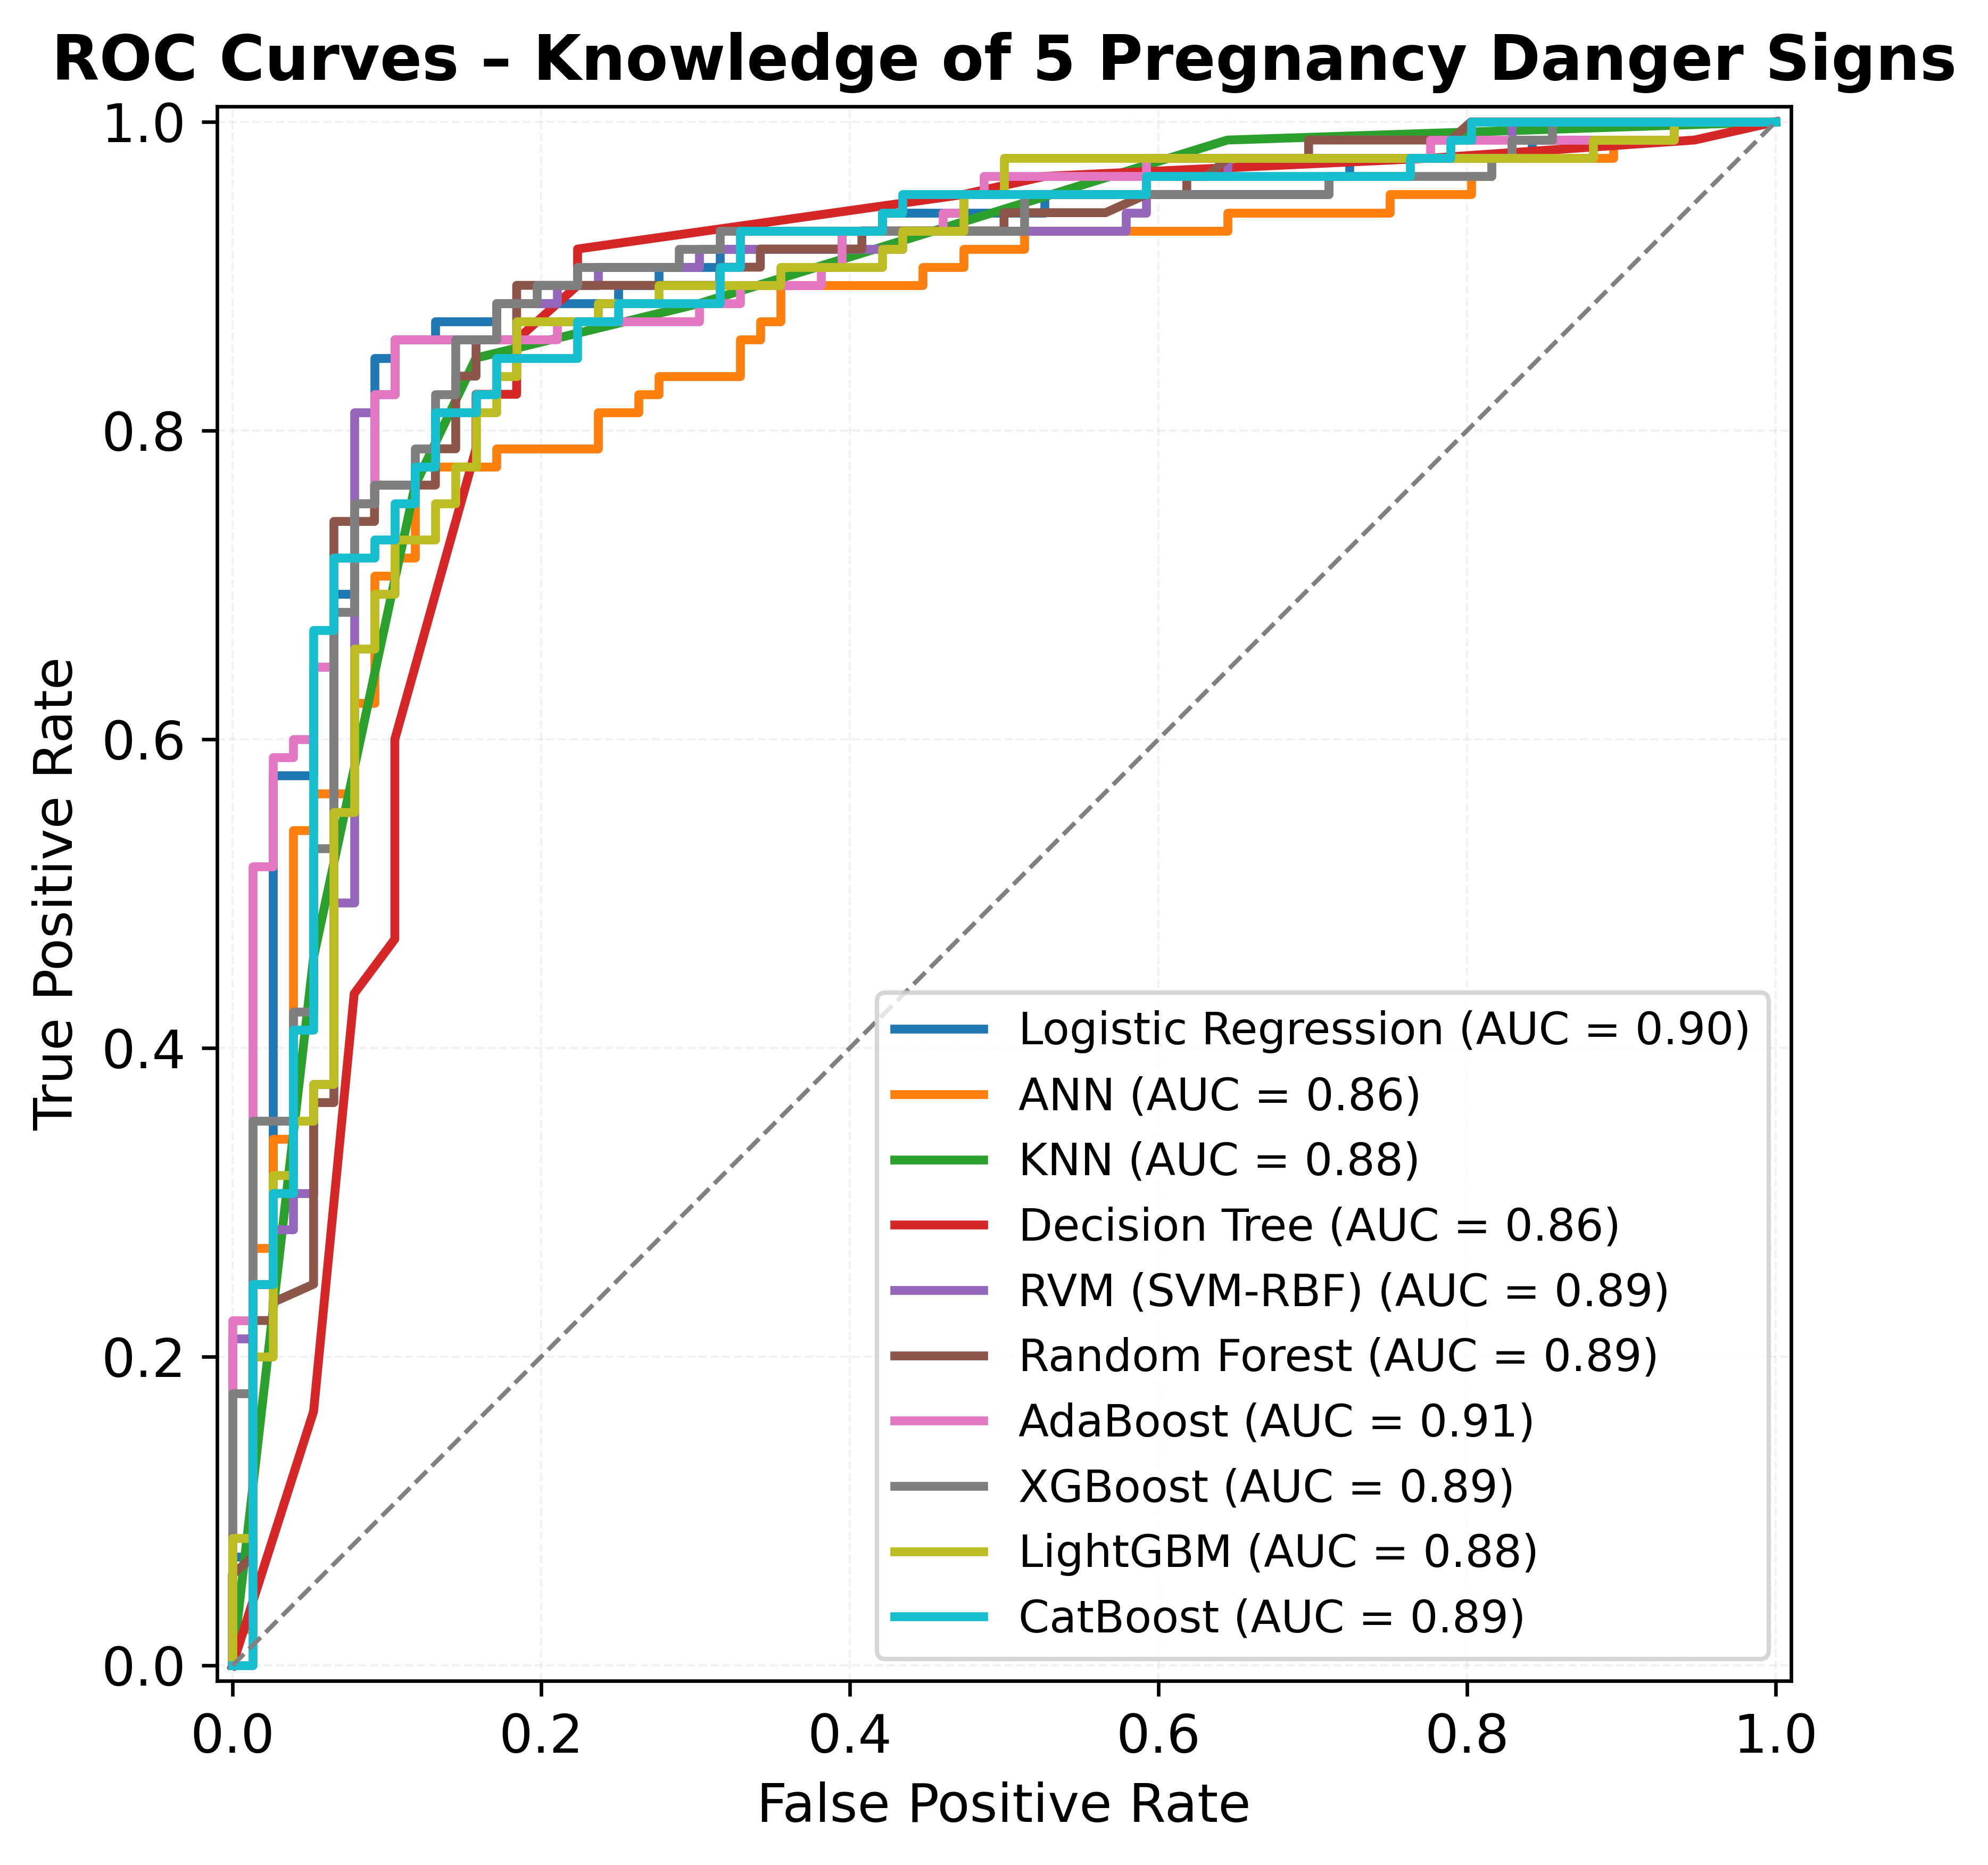

In [42]:
import matplotlib.pyplot as plt
from sklearn.metrics import RocCurveDisplay

plt.figure(figsize=(8, 6), dpi=600)  # High DPI for publication

# Color palette
colors = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728", "#9467bd",
          "#8c564b", "#e377c2", "#7f7f7f", "#bcbd22", "#17becf"]

for idx, (name, model) in enumerate(models.items()):
    if hasattr(model, "predict_proba"):
        RocCurveDisplay.from_estimator(
            model,
            X_test_sel,
            y_test,
            name=name,
            ax=plt.gca(),
            color=colors[idx % len(colors)]
        )

plt.plot([0, 1], [0, 1], linestyle="--", color="gray", linewidth=1)
plt.title("ROC Curves – Knowledge of 5 Pregnancy Danger Signs", fontsize=14, fontweight='bold')
plt.xlabel("False Positive Rate", fontsize=12)
plt.ylabel("True Positive Rate", fontsize=12)
plt.legend(loc="lower right", fontsize=10)
plt.grid(alpha=0.3)
plt.tight_layout()

# Save as TIFF
plt.savefig("/kaggle/working/ROC_combined.tiff", format="tiff")
plt.show()


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


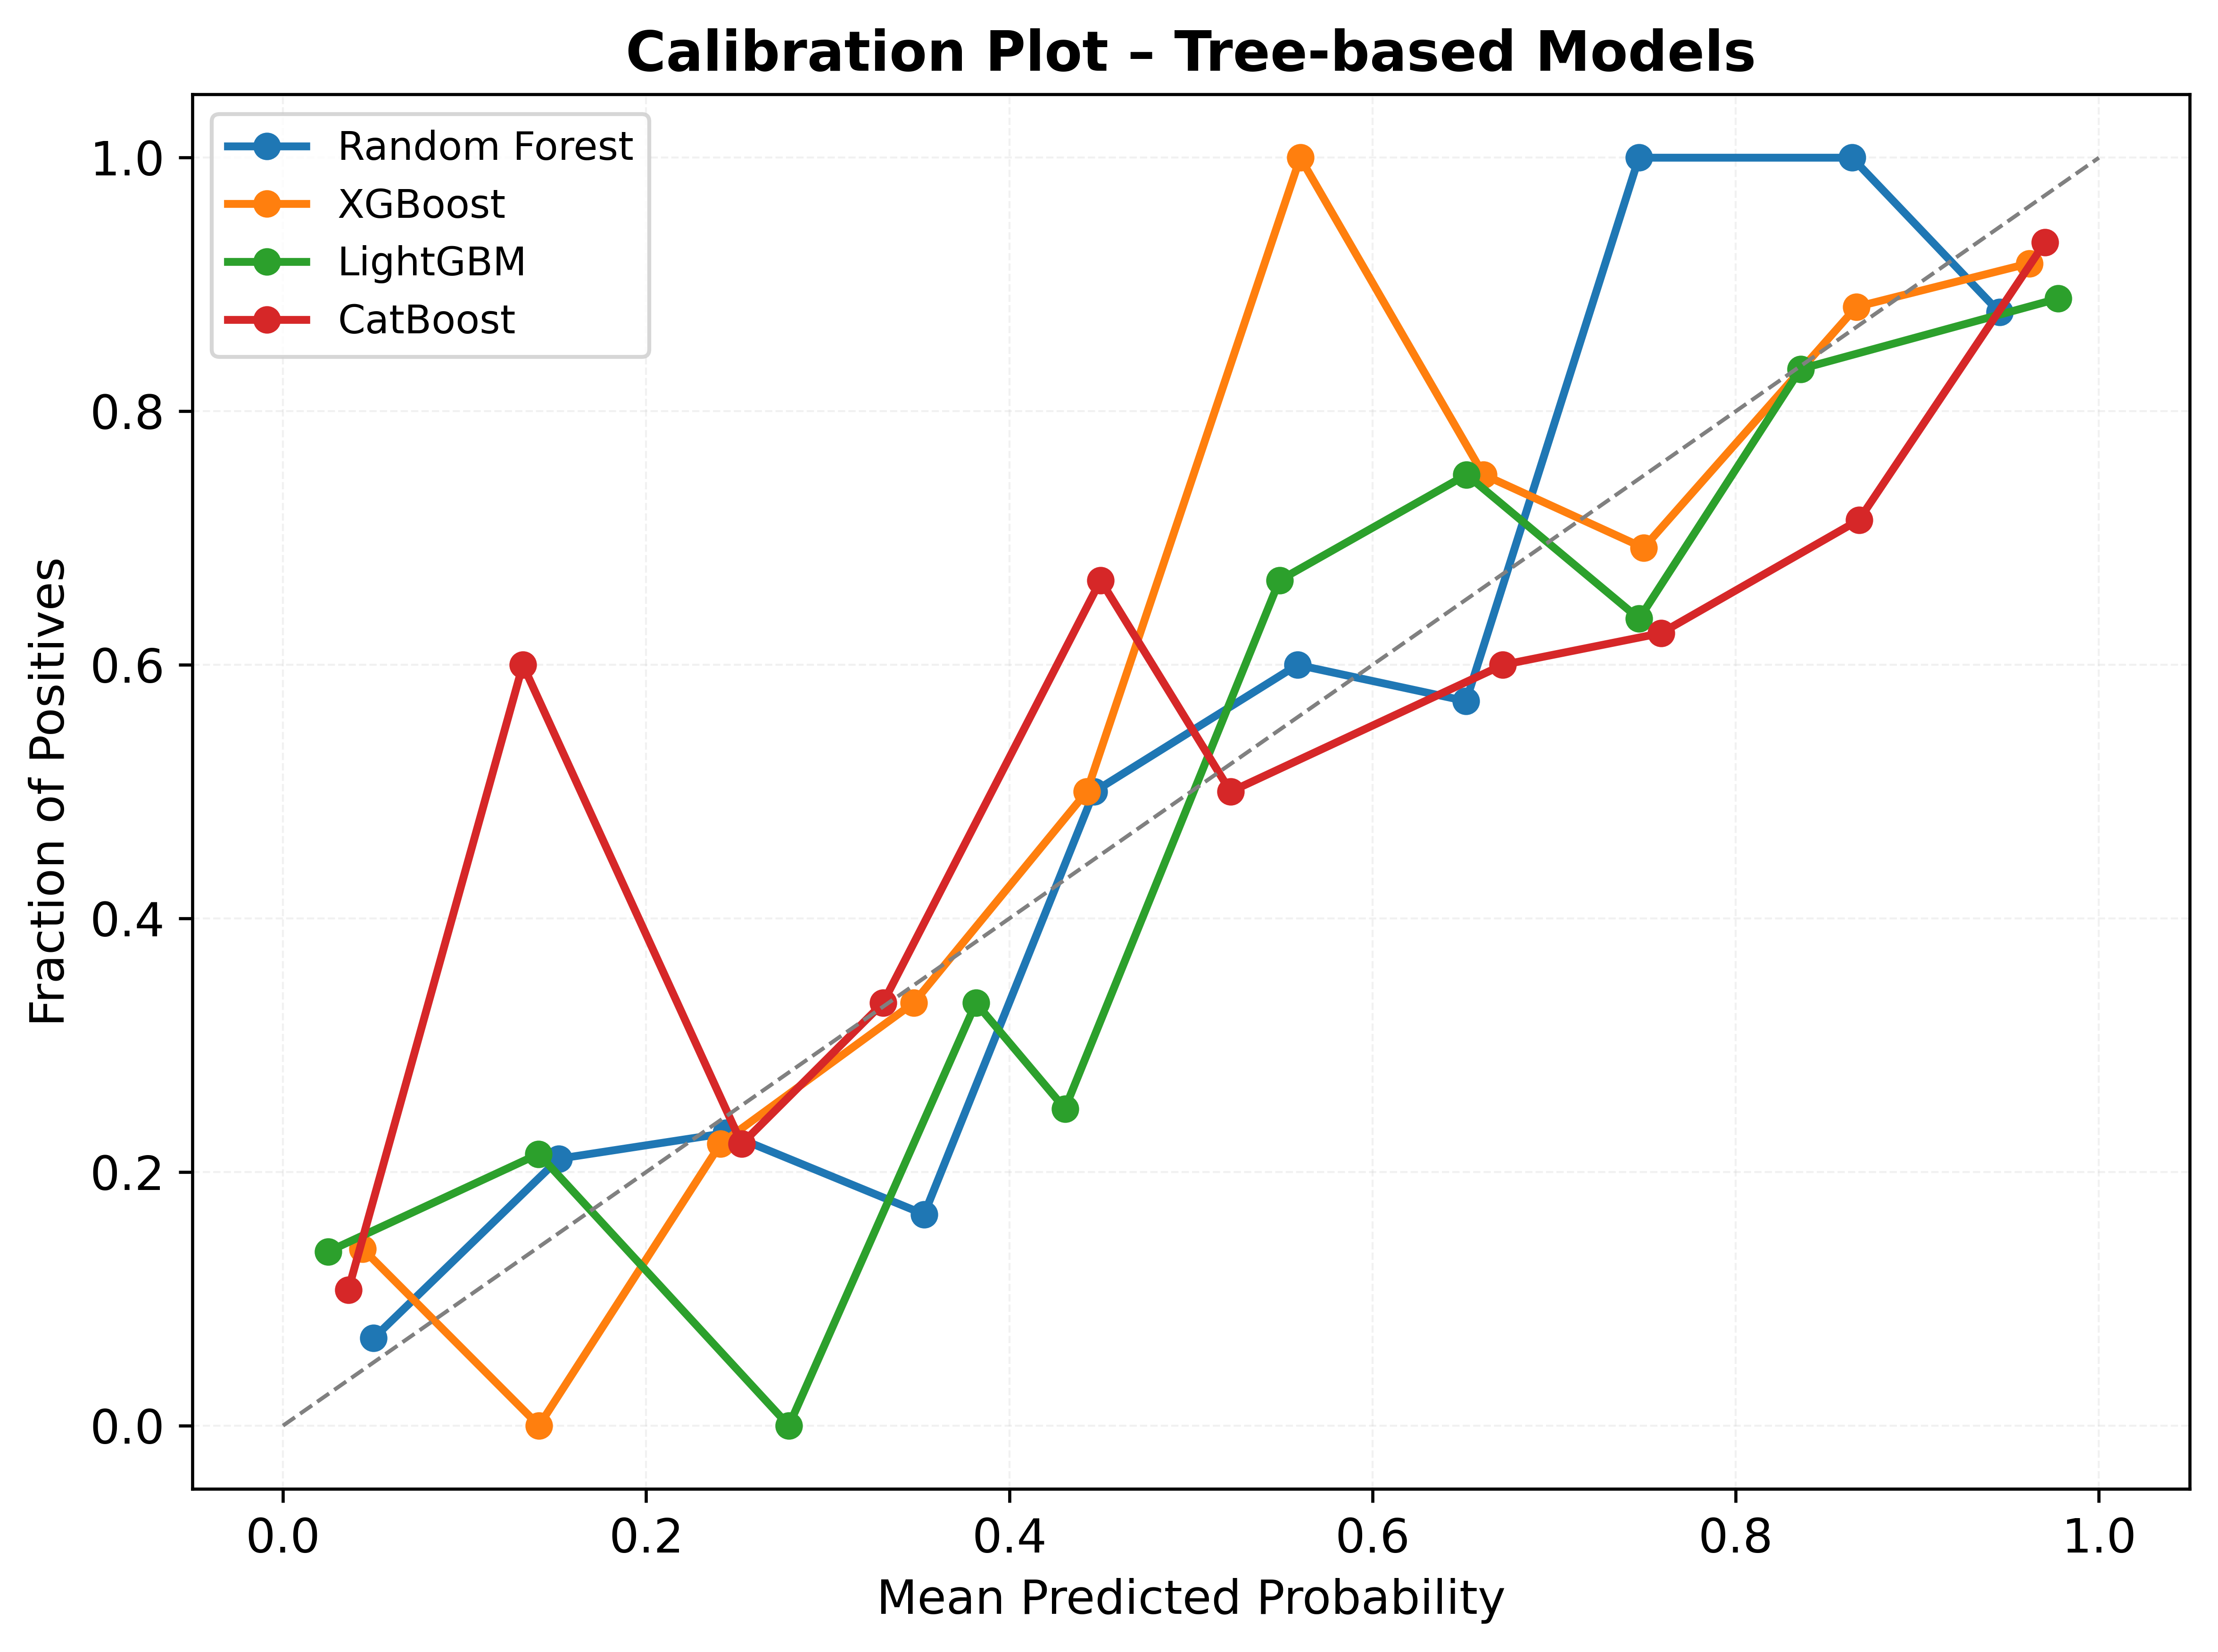

In [43]:
from sklearn.calibration import calibration_curve

plt.figure(figsize=(8, 6), dpi=600)

tree_models = ["Random Forest", "XGBoost", "LightGBM", "CatBoost"]
colors_tree = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728"]

for idx, name in enumerate(tree_models):
    model = models[name]
    y_prob = model.predict_proba(X_test_sel)[:, 1]
    prob_true, prob_pred = calibration_curve(y_test, y_prob, n_bins=10)

    plt.plot(prob_pred, prob_true, marker='o', color=colors_tree[idx], linewidth=2, label=name)

plt.plot([0, 1], [0, 1], linestyle='--', color='gray', linewidth=1)
plt.title("Calibration Plot – Tree-based Models", fontsize=14, fontweight='bold')
plt.xlabel("Mean Predicted Probability", fontsize=12)
plt.ylabel("Fraction of Positives", fontsize=12)
plt.legend(fontsize=10)
plt.grid(alpha=0.3)
plt.tight_layout()

# Save as TIFF
plt.savefig("/kaggle/working/Calibration_plot.tiff", format="tiff")
plt.show()


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


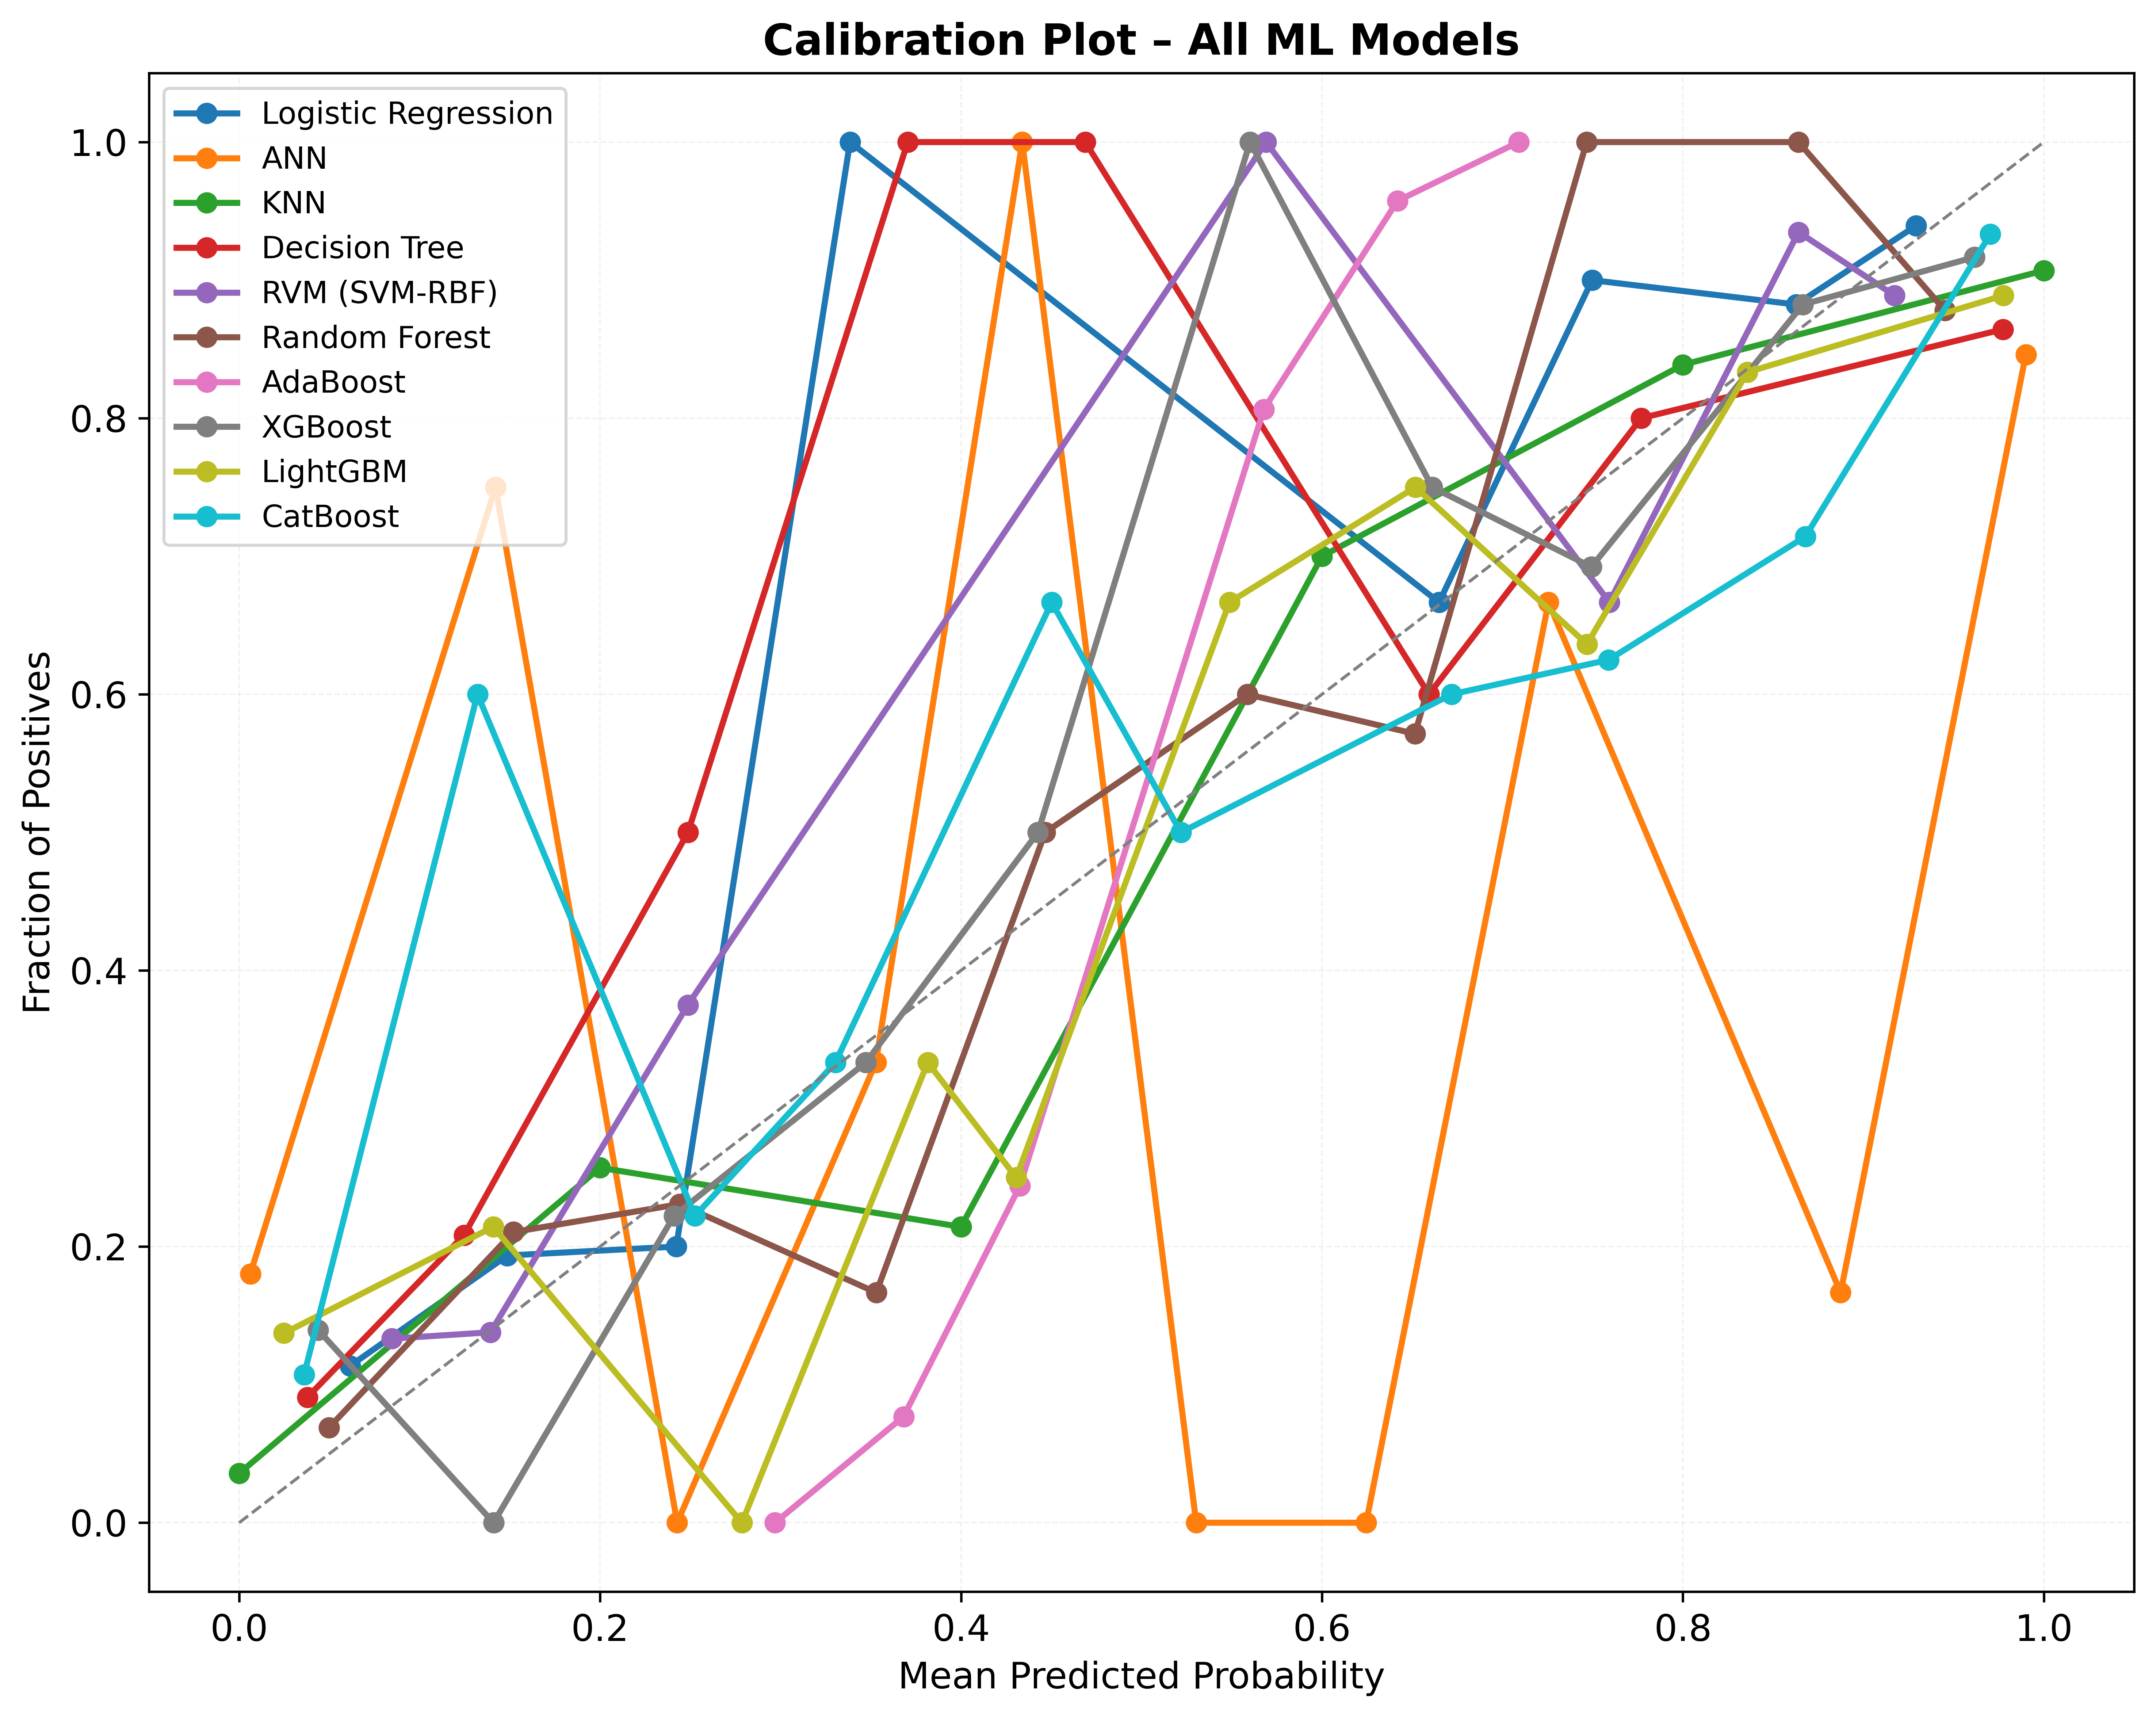

In [44]:
from sklearn.calibration import calibration_curve
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 8), dpi=600)

# Color palette for 10 models
colors = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728", "#9467bd",
          "#8c564b", "#e377c2", "#7f7f7f", "#bcbd22", "#17becf"]

for idx, (name, model) in enumerate(models.items()):
    # Some models (like KNN or ANN) might fail if they don't have predict_proba
    try:
        y_prob = model.predict_proba(X_test_sel)[:, 1]
    except:
        print(f"Skipping calibration for {name} (no predict_proba)")
        continue

    prob_true, prob_pred = calibration_curve(y_test, y_prob, n_bins=10)

    plt.plot(prob_pred, prob_true, marker='o', color=colors[idx % len(colors)],
             linewidth=2, label=name)

# Reference line
plt.plot([0, 1], [0, 1], linestyle='--', color='gray', linewidth=1)

plt.title("Calibration Plot – All ML Models", fontsize=14, fontweight='bold')
plt.xlabel("Mean Predicted Probability", fontsize=12)
plt.ylabel("Fraction of Positives", fontsize=12)
plt.legend(fontsize=10, loc="upper left")
plt.grid(alpha=0.3)
plt.tight_layout()

# Save as TIFF for publication
plt.savefig("/kaggle/working/Calibration_All_Models.tiff", format="tiff")
plt.show()


In [46]:
import shap
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import os

# Convert selected features back to DataFrame
X_test_sel_df = pd.DataFrame(X_test_sel, columns=selected_features)
X_train_sel_df = pd.DataFrame(X_train_sel, columns=selected_features)

# Create output folder if not exist
os.makedirs("/kaggle/working/SHAP_all_models", exist_ok=True)

# Define models and colors
model_colors = {
    "Logistic Regression": "#1f77b4",
    "KNN": "#ff7f0e",
    "SVM": "#2ca02c",
    "Random Forest": "#9467bd",
    "ANN": "#8c564b",
    "DT": "#e377c2",
    "RVM": "#7f7f7f",
    "XGBoost": "#17becf",
    "LightGBM": "#bcbd22",
    "CatBoost": "#d62728",
    "AdaBoost": "#ff7f50"
}

# Loop through models
for name, model in models.items():
    print(f"Processing SHAP for {name}...")
    
    try:
        # -------------------
        # Tree-based models
        # -------------------
        if name in ["Random Forest", "XGBoost", "LightGBM", "CatBoost", "AdaBoost", "DT"]:
            # XGBoost workaround
            if name == "XGBoost":
                try:
                    model_for_shap = model.get_booster()  # SHAP expects Booster
                except:
                    model_for_shap = model  # fallback
            # CatBoost workaround
            elif name == "CatBoost":
                try:
                    model_for_shap = model
                except:
                    model_for_shap = model
            else:
                model_for_shap = model

            explainer = shap.TreeExplainer(model_for_shap)
            shap_values = explainer(X_test_sel_df)

            if isinstance(shap_values, list):  # older SHAP
                shap_vals = shap_values[1]
            else:
                shap_vals = shap_values.values
                if shap_vals.ndim == 3:
                    shap_vals = shap_vals[:, :, 1]  # class 1

        # -------------------
        # Non-tree models
        # -------------------
        else:
            # Use small subset as background for KernelExplainer (slow)
            background = X_train_sel_df.sample(min(100, X_train_sel_df.shape[0]), random_state=123)
            explainer = shap.KernelExplainer(model.predict_proba, background)
            shap_vals = explainer.shap_values(X_test_sel_df, nsamples=100)[1]  # class 1

        # -------------------
        # Compute mean absolute SHAP values
        # -------------------
        shap_importance = np.abs(shap_vals).mean(axis=0)
        importance_df = pd.DataFrame({
            "Feature": X_test_sel_df.columns,
            "Importance": shap_importance
        }).sort_values(by="Importance", ascending=True)

        # -------------------
        # Plot horizontal bar
        # -------------------
        plt.figure(figsize=(8,6), dpi=600)
        plt.barh(
            importance_df['Feature'],
            importance_df['Importance'],
            color=model_colors.get(name, "#1f77b4")
        )
        plt.xlabel("Mean |SHAP Value|", fontsize=12)
        plt.ylabel("Feature", fontsize=12)
        plt.title(f"Feature Importance – {name}", fontsize=14, fontweight='bold')
        plt.grid(axis='x', alpha=0.3)
        plt.gca().set_facecolor("white")
        plt.tight_layout()

        # Save as TIFF
        filename = f"/kaggle/working/SHAP_all_models/SHAP_{name.replace(' ', '_')}.tiff"
        plt.savefig(filename, format="tiff")
        plt.close()
        print(f"Saved: {filename}")

    except Exception as e:
        print(f"SHAP failed for {name}: {e}")


Processing SHAP for Logistic Regression...


  0%|          | 0/161 [00:00<?, ?it/s]

SHAP failed for Logistic Regression: All arrays must be of the same length
Processing SHAP for ANN...


  0%|          | 0/161 [00:00<?, ?it/s]

SHAP failed for ANN: All arrays must be of the same length
Processing SHAP for KNN...


...

SHAP failed for KNN: All arrays must be of the same length
Processing SHAP for Decision Tree...


  0%|          | 0/161 [00:00<?, ?it/s]

SHAP failed for Decision Tree: All arrays must be of the same length
Processing SHAP for RVM (SVM-RBF)...


  0%|          | 0/161 [00:00<?, ?it/s]

SHAP failed for RVM (SVM-RBF): All arrays must be of the same length
Processing SHAP for Random Forest...
Saved: /kaggle/working/SHAP_all_models/SHAP_Random_Forest.tiff
Processing SHAP for AdaBoost...
SHAP failed for AdaBoost: Model type not yet supported by TreeExplainer: <class 'sklearn.ensemble._weight_boosting.AdaBoostClassifier'>
Processing SHAP for XGBoost...
SHAP failed for XGBoost: could not convert string to float: '[5.3115267E-1]'
Processing SHAP for LightGBM...
Saved: /kaggle/working/SHAP_all_models/SHAP_LightGBM.tiff
Processing SHAP for CatBoost...
Saved: /kaggle/working/SHAP_all_models/SHAP_CatBoost.tiff


In [47]:
import shap
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import os

# High-DPI for publication
dpi = 600

# Convert selected features to DataFrame
X_test_sel_df = pd.DataFrame(X_test_sel, columns=selected_features)
X_train_sel_df = pd.DataFrame(X_train_sel, columns=selected_features)

# Folder to save plots
os.makedirs("/kaggle/working/SHAP_all_models", exist_ok=True)

# Loop over all models
for name, model in models.items():
    print(f"\nGenerating SHAP for: {name}")
    
    try:
        # -------------------
        # Tree-based models
        # -------------------
        if name in ["Random Forest", "XGBoost", "LightGBM", "CatBoost", "AdaBoost", "Decision Tree"]:
            # Workarounds for specific tree models
            if name == "XGBoost":
                try:
                    model_for_shap = model.get_booster()
                except:
                    model_for_shap = model
            elif name == "CatBoost":
                model_for_shap = model
            else:
                model_for_shap = model

            explainer = shap.TreeExplainer(model_for_shap)
            shap_values = explainer(X_test_sel_df)
            
            # For binary classification, class 1
            if isinstance(shap_values, list):
                shap_vals_plot = shap_values[1]
            else:
                shap_vals_plot = shap_values.values
                if shap_vals_plot.ndim == 3:
                    shap_vals_plot = shap_vals_plot[:, :, 1]

        # -------------------
        # Non-tree models
        # -------------------
        else:
            # Use small subset as background for KernelExplainer (slower)
            background = X_train_sel_df.sample(min(100, X_train_sel_df.shape[0]), random_state=123)
            explainer = shap.KernelExplainer(model.predict_proba, background)
            shap_vals_plot = explainer.shap_values(X_test_sel_df, nsamples=100)[1]  # class 1

        # -------------------
        # SHAP summary bar plot (feature importance only)
        # -------------------
        shap_importance = np.abs(shap_vals_plot).mean(axis=0)
        importance_df = pd.DataFrame({
            "Feature": X_test_sel_df.columns,
            "Importance": shap_importance
        }).sort_values(by="Importance", ascending=True)

        plt.figure(figsize=(8,6), dpi=dpi)
        plt.barh(
            importance_df['Feature'],
            importance_df['Importance'],
            color="#1f77b4"
        )
        plt.xlabel("Mean |SHAP Value|", fontsize=12)
        plt.ylabel("Feature", fontsize=12)
        plt.title(f"Feature Importance – {name}", fontsize=14, fontweight='bold')
        plt.grid(axis='x', alpha=0.3)
        plt.gca().set_facecolor("white")
        plt.tight_layout()

        # Save as TIFF
        filename = f"/kaggle/working/SHAP_all_models/SHAP_FeatureImportance_{name.replace(' ','_')}.tiff"
        plt.savefig(filename, format="tiff")
        plt.close()
        print(f"Saved: {filename}")

    except Exception as e:
        print(f"Could not compute SHAP for {name}: {e}")



Generating SHAP for: Logistic Regression


  0%|          | 0/161 [00:00<?, ?it/s]

Could not compute SHAP for Logistic Regression: All arrays must be of the same length

Generating SHAP for: ANN


  0%|          | 0/161 [00:00<?, ?it/s]

Could not compute SHAP for ANN: All arrays must be of the same length

Generating SHAP for: KNN


  0%|          | 0/161 [00:00<?, ?it/s]

Could not compute SHAP for KNN: All arrays must be of the same length

Generating SHAP for: Decision Tree
Saved: /kaggle/working/SHAP_all_models/SHAP_FeatureImportance_Decision_Tree.tiff

Generating SHAP for: RVM (SVM-RBF)


  0%|          | 0/161 [00:00<?, ?it/s]

Could not compute SHAP for RVM (SVM-RBF): All arrays must be of the same length

Generating SHAP for: Random Forest
Saved: /kaggle/working/SHAP_all_models/SHAP_FeatureImportance_Random_Forest.tiff

Generating SHAP for: AdaBoost
Could not compute SHAP for AdaBoost: Model type not yet supported by TreeExplainer: <class 'sklearn.ensemble._weight_boosting.AdaBoostClassifier'>

Generating SHAP for: XGBoost
Could not compute SHAP for XGBoost: could not convert string to float: '[5.3115267E-1]'

Generating SHAP for: LightGBM
Saved: /kaggle/working/SHAP_all_models/SHAP_FeatureImportance_LightGBM.tiff

Generating SHAP for: CatBoost
Saved: /kaggle/working/SHAP_all_models/SHAP_FeatureImportance_CatBoost.tiff


In [48]:
from sklearn.inspection import permutation_importance

for name, model in models.items():
    print(f"\nProcessing feature importance for {name}...")
    
    try:
        if name in ["Random Forest", "LightGBM", "CatBoost"]:
            # SHAP for trees
            explainer = shap.TreeExplainer(model)
            shap_values = explainer(X_test_sel_df)
            shap_vals = shap_values.values if not isinstance(shap_values, list) else shap_values[1]
            importance = np.abs(shap_vals).mean(axis=0)

        else:
            # Permutation importance for non-tree models
            r = permutation_importance(model, X_test_sel, y_test, n_repeats=10, random_state=123, n_jobs=-1)
            importance = r.importances_mean

        # Build DataFrame and sort
        importance_df = pd.DataFrame({
            "Feature": X_test_sel_df.columns,
            "Importance": importance
        }).sort_values(by="Importance", ascending=True)

        # Plot horizontal bar
        plt.figure(figsize=(8,6), dpi=600)
        plt.barh(
            importance_df['Feature'],
            importance_df['Importance'],
            color=model_colors.get(name, "#1f77b4")
        )
        plt.xlabel("Feature Importance", fontsize=12)
        plt.ylabel("Feature", fontsize=12)
        plt.title(f"Feature Importance – {name}", fontsize=14, fontweight='bold')
        plt.grid(axis='x', alpha=0.3)
        plt.gca().set_facecolor("white")
        plt.tight_layout()

        # Save TIFF
        filename = f"/kaggle/working/SHAP_all_models/FeatureImportance_{name.replace(' ','_')}.tiff"
        plt.savefig(filename, format="tiff")
        plt.close()
        print(f"Saved: {filename}")

    except Exception as e:
        print(f"Feature importance failed for {name}: {e}")



Processing feature importance for Logistic Regression...
Saved: /kaggle/working/SHAP_all_models/FeatureImportance_Logistic_Regression.tiff

Processing feature importance for ANN...
Saved: /kaggle/working/SHAP_all_models/FeatureImportance_ANN.tiff

Processing feature importance for KNN...
Saved: /kaggle/working/SHAP_all_models/FeatureImportance_KNN.tiff

Processing feature importance for Decision Tree...
Saved: /kaggle/working/SHAP_all_models/FeatureImportance_Decision_Tree.tiff

Processing feature importance for RVM (SVM-RBF)...
Saved: /kaggle/working/SHAP_all_models/FeatureImportance_RVM_(SVM-RBF).tiff

Processing feature importance for Random Forest...
Feature importance failed for Random Forest: Per-column arrays must each be 1-dimensional

Processing feature importance for AdaBoost...
Saved: /kaggle/working/SHAP_all_models/FeatureImportance_AdaBoost.tiff

Processing feature importance for XGBoost...
Saved: /kaggle/working/SHAP_all_models/FeatureImportance_XGBoost.tiff

Processing 

In [54]:
import shap
import lime
import lime.lime_tabular
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import os

# --------------------------
# Prepare DataFrames
# --------------------------
X_test_df = pd.DataFrame(X_test_sel, columns=selected_features)
X_train_df = pd.DataFrame(X_train_sel, columns=selected_features)

# --------------------------
# Output folders
# --------------------------
os.makedirs("/kaggle/working/SHAP_Beeswarm", exist_ok=True)
os.makedirs("/kaggle/working/LIME_FeatureImportance", exist_ok=True)

# --------------------------
# Models
# --------------------------
tree_models = ["Random Forest", "XGBoost", "LightGBM", "CatBoost", "DT", "AdaBoost"]
non_tree_models = ["Logistic Regression", "KNN", "ANN", "RVM (SVM-RBF)"]

# --------------------------
# SHAP for tree models
# --------------------------
for name in tree_models:
    if name not in models:
        print(f"{name} not found. Skipping.")
        continue

    model = models[name]
    print(f"\nGenerating SHAP for {name}")

    try:
        # Handle XGBoost booster
        if name == "XGBoost":
            model_for_shap = model.get_booster()
        else:
            model_for_shap = model

        explainer = shap.TreeExplainer(model_for_shap)
        shap_values = explainer(X_test_df)

        # Get numpy array for plotting
        if hasattr(shap_values, "values"):
            shap_vals_plot = shap_values.values
            if shap_vals_plot.ndim == 3:  # binary
                shap_vals_plot = shap_vals_plot[:, :, 1]
        else:
            shap_vals_plot = shap_values

        # Plot beeswarm
        plt.figure(figsize=(8,6), dpi=600)
        shap.summary_plot(
            shap_vals_plot,
            X_test_df,
            feature_names=selected_features,
            plot_type="dot",
            max_display=15,
            show=False
        )
        plt.title(f"SHAP Beeswarm – {name}", fontsize=14, fontweight='bold')
        plt.tight_layout()
        filename = f"/kaggle/working/SHAP_Beeswarm/SHAP_Beeswarm_{name.replace(' ','_')}.tiff"
        plt.savefig(filename, format="tiff")
        plt.close()
        print(f"Saved SHAP plot: {filename}")

    except Exception as e:
        print(f"SHAP failed for {name}: {e}")

# --------------------------
# LIME for non-tree models
# --------------------------
for name in non_tree_models:
    if name not in models:
        print(f"{name} not found. Skipping.")
        continue

    model = models[name]
    print(f"\nGenerating LIME for {name}")

    try:
        explainer = lime.lime_tabular.LimeTabularExplainer(
            X_train_df.values,
            feature_names=selected_features,
            class_names=['0','1'],
            mode='classification'
        )

        # Pick a single instance or batch
        instance = X_test_df.values[0]

        lime_exp = explainer.explain_instance(instance, model.predict_proba, num_features=15)
        # Plot horizontal bar
        fig = lime_exp.as_pyplot_figure()
        plt.tight_layout()
        filename = f"/kaggle/working/LIME_FeatureImportance/LIME_{name.replace(' ','_')}.tiff"
        fig.savefig(filename, format="tiff", dpi=600)
        plt.close()
        print(f"Saved LIME plot: {filename}")

    except Exception as e:
        print(f"LIME failed for {name}: {e}")



Generating SHAP for Random Forest


/tmp/ipykernel_55/414399097.py:58: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


Saved SHAP plot: /kaggle/working/SHAP_Beeswarm/SHAP_Beeswarm_Random_Forest.tiff

Generating SHAP for XGBoost
SHAP failed for XGBoost: could not convert string to float: '[5.3115267E-1]'

Generating SHAP for LightGBM


/tmp/ipykernel_55/414399097.py:58: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


Saved SHAP plot: /kaggle/working/SHAP_Beeswarm/SHAP_Beeswarm_LightGBM.tiff

Generating SHAP for CatBoost


/tmp/ipykernel_55/414399097.py:58: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


Saved SHAP plot: /kaggle/working/SHAP_Beeswarm/SHAP_Beeswarm_CatBoost.tiff
DT not found. Skipping.

Generating SHAP for AdaBoost
SHAP failed for AdaBoost: Model type not yet supported by TreeExplainer: <class 'sklearn.ensemble._weight_boosting.AdaBoostClassifier'>

Generating LIME for Logistic Regression
Saved LIME plot: /kaggle/working/LIME_FeatureImportance/LIME_Logistic_Regression.tiff

Generating LIME for KNN
Saved LIME plot: /kaggle/working/LIME_FeatureImportance/LIME_KNN.tiff

Generating LIME for ANN
Saved LIME plot: /kaggle/working/LIME_FeatureImportance/LIME_ANN.tiff

Generating LIME for RVM (SVM-RBF)
Saved LIME plot: /kaggle/working/LIME_FeatureImportance/LIME_RVM_(SVM-RBF).tiff


In [53]:
import shap
import matplotlib.pyplot as plt
import pandas as pd
import os

# --------------------------
# Prepare DataFrames
# --------------------------
X_test_sel_df = pd.DataFrame(X_test_sel, columns=selected_features)
X_train_sel_df = pd.DataFrame(X_train_sel, columns=selected_features)

# --------------------------
# Output folder
# --------------------------
os.makedirs("/kaggle/working/SHAP_Beeswarm", exist_ok=True)

# --------------------------
# Tree-based models for SHAP beeswarm
# --------------------------
tree_models = ["Random Forest", "XGBoost", "LightGBM", "CatBoost", "DT", "AdaBoost"]

# Colors for beeswarm (optional, matplotlib default)
colors = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728", "#9467bd", "#bcbd22"]

# --------------------------
# Loop over tree models
# --------------------------
for idx, name in enumerate(tree_models):
    if name not in models:
        print(f"Model {name} not found in models dict. Skipping.")
        continue

    model = models[name]
    print(f"\nGenerating SHAP beeswarm for: {name}")

    try:
        # XGBoost needs Booster
        if name == "XGBoost":
            try:
                model_for_shap = model.get_booster()
            except:
                model_for_shap = model
        else:
            model_for_shap = model

        # TreeExplainer
        explainer = shap.TreeExplainer(model_for_shap)
        shap_values = explainer(X_test_sel_df)

        # Handle output
        if isinstance(shap_values, list):  # older versions
            shap_vals_plot = shap_values[1]
        else:
            shap_vals_plot = shap_values.values
            if shap_vals_plot.ndim == 3:
                shap_vals_plot = shap_vals_plot[:, :, 1]  # class 1

        # Plot beeswarm
        plt.figure(figsize=(8,6), dpi=600)
        shap.summary_plot(
            shap_vals_plot,
            X_test_sel_df,
            feature_names=selected_features,
            plot_type="dot",  # beeswarm
            max_display=15,
            show=False
        )
        plt.title(f"SHAP Beeswarm – {name}", fontsize=14, fontweight='bold')
        plt.tight_layout()

        # Save as TIFF
        filename = f"/kaggle/working/SHAP_Beeswarm/SHAP_Beeswarm_{name.replace(' ','_')}.tiff"
        plt.savefig(filename, format="tiff")
        plt.close()
        print(f"Saved: {filename}")

    except Exception as e:
        print(f"Could not compute SHAP for {name}: {e}")



Generating SHAP beeswarm for: Random Forest


/tmp/ipykernel_55/1468184557.py:60: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


Saved: /kaggle/working/SHAP_Beeswarm/SHAP_Beeswarm_Random_Forest.tiff

Generating SHAP beeswarm for: XGBoost
Could not compute SHAP for XGBoost: could not convert string to float: '[5.3115267E-1]'

Generating SHAP beeswarm for: LightGBM


/tmp/ipykernel_55/1468184557.py:60: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


Saved: /kaggle/working/SHAP_Beeswarm/SHAP_Beeswarm_LightGBM.tiff

Generating SHAP beeswarm for: CatBoost


/tmp/ipykernel_55/1468184557.py:60: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


Saved: /kaggle/working/SHAP_Beeswarm/SHAP_Beeswarm_CatBoost.tiff
Model DT not found in models dict. Skipping.

Generating SHAP beeswarm for: AdaBoost
Could not compute SHAP for AdaBoost: Model type not yet supported by TreeExplainer: <class 'sklearn.ensemble._weight_boosting.AdaBoostClassifier'>


In [55]:
import shap
import lime
import lime.lime_tabular
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import os

# --------------------------
# Prepare DataFrames
# --------------------------
X_test_df = pd.DataFrame(X_test_sel, columns=selected_features)
X_train_df = pd.DataFrame(X_train_sel, columns=selected_features)

# --------------------------
# Output folders
# --------------------------
os.makedirs("/kaggle/working/SHAP_Beeswarm", exist_ok=True)
os.makedirs("/kaggle/working/LIME_FeatureImportance", exist_ok=True)

# --------------------------
# Models
# --------------------------
tree_models = ["Random Forest", "XGBoost", "LightGBM", "CatBoost", "DT", "AdaBoost"]
non_tree_models = ["Logistic Regression", "KNN", "ANN", "RVM (SVM-RBF)"]

# --------------------------
# SHAP for tree models
# --------------------------
for name in tree_models:
    if name not in models:
        print(f"{name} not found. Skipping.")
        continue

    model = models[name]
    print(f"\nGenerating SHAP for {name}")

    try:
        # Handle XGBoost booster
        if name == "XGBoost":
            model_for_shap = model.get_booster()
        else:
            model_for_shap = model

        explainer = shap.TreeExplainer(model_for_shap)
        shap_values = explainer(X_test_df)

        # Get numpy array for plotting
        if hasattr(shap_values, "values"):
            shap_vals_plot = shap_values.values
            if shap_vals_plot.ndim == 3:  # binary
                shap_vals_plot = shap_vals_plot[:, :, 1]
        else:
            shap_vals_plot = shap_values

        # Plot beeswarm
        plt.figure(figsize=(8,6), dpi=600)
        shap.summary_plot(
            shap_vals_plot,
            X_test_df,
            feature_names=selected_features,
            plot_type="dot",
            max_display=15,
            show=False
        )
        plt.title(f"SHAP Beeswarm – {name}", fontsize=14, fontweight='bold')
        plt.tight_layout()
        filename = f"/kaggle/working/SHAP_Beeswarm/SHAP_Beeswarm_{name.replace(' ','_')}.tiff"
        plt.savefig(filename, format="tiff")
        plt.close()
        print(f"Saved SHAP plot: {filename}")

    except Exception as e:
        print(f"SHAP failed for {name}: {e}")

# --------------------------
# LIME for non-tree models
# --------------------------
for name in non_tree_models:
    if name not in models:
        print(f"{name} not found. Skipping.")
        continue

    model = models[name]
    print(f"\nGenerating LIME for {name}")

    try:
        explainer = lime.lime_tabular.LimeTabularExplainer(
            X_train_df.values,
            feature_names=selected_features,
            class_names=['0','1'],
            mode='classification'
        )

        # Pick a single instance or batch
        instance = X_test_df.values[0]

        lime_exp = explainer.explain_instance(instance, model.predict_proba, num_features=15)
        # Plot horizontal bar
        fig = lime_exp.as_pyplot_figure()
        plt.tight_layout()
        filename = f"/kaggle/working/LIME_FeatureImportance/LIME_{name.replace(' ','_')}.tiff"
        fig.savefig(filename, format="tiff", dpi=600)
        plt.close()
        print(f"Saved LIME plot: {filename}")

    except Exception as e:
        print(f"LIME failed for {name}: {e}")



Generating SHAP for Random Forest


/tmp/ipykernel_55/414399097.py:58: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


Saved SHAP plot: /kaggle/working/SHAP_Beeswarm/SHAP_Beeswarm_Random_Forest.tiff

Generating SHAP for XGBoost
SHAP failed for XGBoost: could not convert string to float: '[5.3115267E-1]'

Generating SHAP for LightGBM


/tmp/ipykernel_55/414399097.py:58: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


Saved SHAP plot: /kaggle/working/SHAP_Beeswarm/SHAP_Beeswarm_LightGBM.tiff

Generating SHAP for CatBoost


/tmp/ipykernel_55/414399097.py:58: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


Saved SHAP plot: /kaggle/working/SHAP_Beeswarm/SHAP_Beeswarm_CatBoost.tiff
DT not found. Skipping.

Generating SHAP for AdaBoost
SHAP failed for AdaBoost: Model type not yet supported by TreeExplainer: <class 'sklearn.ensemble._weight_boosting.AdaBoostClassifier'>

Generating LIME for Logistic Regression
Saved LIME plot: /kaggle/working/LIME_FeatureImportance/LIME_Logistic_Regression.tiff

Generating LIME for KNN
Saved LIME plot: /kaggle/working/LIME_FeatureImportance/LIME_KNN.tiff

Generating LIME for ANN
Saved LIME plot: /kaggle/working/LIME_FeatureImportance/LIME_ANN.tiff

Generating LIME for RVM (SVM-RBF)
Saved LIME plot: /kaggle/working/LIME_FeatureImportance/LIME_RVM_(SVM-RBF).tiff


In [56]:
import os
import shap
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from lime.lime_tabular import LimeTabularExplainer

# --------------------------
# Prepare DataFrames
# --------------------------
X_test_sel_df = pd.DataFrame(X_test_sel, columns=selected_features)
X_train_sel_df = pd.DataFrame(X_train_sel, columns=selected_features)

# --------------------------
# Output folders
# --------------------------
shap_folder = "/kaggle/working/SHAP_Beeswarm_AllModels"
lime_folder = "/kaggle/working/LIME_FeatureImportance_AllModels"
os.makedirs(shap_folder, exist_ok=True)
os.makedirs(lime_folder, exist_ok=True)

# --------------------------
# Define models categories
# --------------------------
tree_models = ["Random Forest", "XGBoost", "LightGBM", "CatBoost", "DT", "AdaBoost"]
non_tree_models = ["Logistic Regression", "KNN", "ANN", "RVM (SVM-RBF)"]

# --------------------------
# SHAP Beeswarm for tree models
# --------------------------
for name in tree_models:
    if name not in models:
        print(f"Model {name} not found. Skipping SHAP.")
        continue
    
    model = models[name]
    print(f"Generating SHAP for {name}...")
    
    try:
        # Special handling
        if name == "XGBoost":
            try:
                model_for_shap = model.get_booster()
            except:
                model_for_shap = model
        else:
            model_for_shap = model

        explainer = shap.TreeExplainer(model_for_shap)
        shap_values = explainer(X_test_sel_df)
        
        # Handle output
        if isinstance(shap_values, list):
            shap_vals_plot = shap_values[1]
        else:
            shap_vals_plot = shap_values.values
            if shap_vals_plot.ndim == 3:
                shap_vals_plot = shap_vals_plot[:, :, 1]  # class 1

        # Plot beeswarm
        plt.figure(figsize=(8,6), dpi=600)
        shap.summary_plot(
            shap_vals_plot,
            X_test_sel_df,
            feature_names=selected_features,
            plot_type="dot",
            max_display=15,
            show=False
        )
        plt.title(f"SHAP Beeswarm – {name}", fontsize=14, fontweight='bold')
        plt.tight_layout()
        filename = os.path.join(shap_folder, f"SHAP_Beeswarm_{name.replace(' ','_')}.tiff")
        plt.savefig(filename, format="tiff")
        plt.close()
        print(f"Saved SHAP plot: {filename}")

    except Exception as e:
        print(f"SHAP failed for {name}: {e}")

# --------------------------
# LIME for non-tree models
# --------------------------
for name in non_tree_models + [m for m in tree_models if m not in ["Random Forest", "LightGBM", "CatBoost"]]:
    if name not in models:
        print(f"Model {name} not found. Skipping LIME.")
        continue
    
    model = models[name]
    print(f"Generating LIME for {name}...")
    
    try:
        explainer = LimeTabularExplainer(
            training_data=np.array(X_train_sel_df),
            feature_names=selected_features,
            class_names=["0","1"],
            mode="classification"
        )
        
        # Use first 50 samples for speed
        lime_scores = []
        for i in range(min(50, X_test_sel_df.shape[0])):
            exp = explainer.explain_instance(
                data_row=X_test_sel_df.iloc[i],
                predict_fn=model.predict_proba,
                num_features=len(selected_features)
            )
            lime_scores.append(dict(exp.as_list()))
        
        # Aggregate importance
        importance_df = pd.DataFrame(lime_scores).fillna(0).abs().mean().sort_values(ascending=True)
        
        # Plot horizontal bar
        plt.figure(figsize=(8,6), dpi=600)
        plt.barh(importance_df.index, importance_df.values, color="#1f77b4")
        plt.xlabel("Mean |LIME Feature Importance|", fontsize=12)
        plt.ylabel("Feature", fontsize=12)
        plt.title(f"LIME Feature Importance – {name}", fontsize=14, fontweight='bold')
        plt.grid(axis='x', alpha=0.3)
        plt.gca().set_facecolor("white")
        plt.tight_layout()
        filename = os.path.join(lime_folder, f"LIME_{name.replace(' ','_')}.tiff")
        plt.savefig(filename, format="tiff")
        plt.close()
        print(f"Saved LIME plot: {filename}")

    except Exception as e:
        print(f"LIME failed for {name}: {e}")


Generating SHAP for Random Forest...


/tmp/ipykernel_55/928917412.py:62: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


Saved SHAP plot: /kaggle/working/SHAP_Beeswarm_AllModels/SHAP_Beeswarm_Random_Forest.tiff
Generating SHAP for XGBoost...
SHAP failed for XGBoost: could not convert string to float: '[5.3115267E-1]'
Generating SHAP for LightGBM...


/tmp/ipykernel_55/928917412.py:62: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


Saved SHAP plot: /kaggle/working/SHAP_Beeswarm_AllModels/SHAP_Beeswarm_LightGBM.tiff
Generating SHAP for CatBoost...


...

Saved LIME plot: /kaggle/working/LIME_FeatureImportance_AllModels/LIME_RVM_(SVM-RBF).tiff
Generating LIME for XGBoost...


/usr/local/lib/python3.12/dist-packages/lime/discretize.py:110: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  ret[feature] = int(self.lambdas[feature](ret[feature]))
/usr/local/lib/python3.12/dist-packages/lime/discretize.py:110: FutureWarning: Series.__setitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To set a value by position, use `ser.iloc[pos] = value`
  ret[feature] = int(self.lambdas[feature](ret[feature]))
/usr/local/lib/python3.12/dist-packages/lime/lime_tabular.py:544: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.

Saved LIME plot: /kaggle/working/LIME_FeatureImportance_AllModels/LIME_XGBoost.tiff
Model DT not found. Skipping LIME.
Generating LIME for AdaBoost...


/usr/local/lib/python3.12/dist-packages/lime/discretize.py:110: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  ret[feature] = int(self.lambdas[feature](ret[feature]))
/usr/local/lib/python3.12/dist-packages/lime/discretize.py:110: FutureWarning: Series.__setitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To set a value by position, use `ser.iloc[pos] = value`
  ret[feature] = int(self.lambdas[feature](ret[feature]))
/usr/local/lib/python3.12/dist-packages/lime/lime_tabular.py:544: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.

Saved LIME plot: /kaggle/working/LIME_FeatureImportance_AllModels/LIME_AdaBoost.tiff


In [60]:
import shap
import matplotlib.pyplot as plt
import pandas as pd
import os

# Prepare DataFrame
X_test_sel_df = pd.DataFrame(X_test_sel, columns=selected_features)

# Output folder
os.makedirs("/kaggle/working/SHAP_Beeswarm", exist_ok=True)

# Get the Decision Tree model
dt_model = models["Decision Tree"]

print("Generating SHAP beeswarm for Decision Tree...")

try:
    # TreeExplainer
    explainer = shap.TreeExplainer(dt_model)
    shap_values = explainer(X_test_sel_df)

    # Handle SHAP output
    if isinstance(shap_values, list):  # older SHAP
        shap_vals_plot = shap_values[1]
    else:
        shap_vals_plot = shap_values.values
        if shap_vals_plot.ndim == 3:  # binary class
            shap_vals_plot = shap_vals_plot[:, :, 1]

    # Plot beeswarm
    plt.figure(figsize=(8,6), dpi=600)
    shap.summary_plot(
        shap_vals_plot,
        X_test_sel_df,
        feature_names=selected_features,
        plot_type="dot",  # beeswarm
        max_display=15,
        show=False
    )
    plt.title("SHAP Beeswarm – Decision Tree", fontsize=14, fontweight='bold')
    plt.tight_layout()

    # Save as TIFF
    filename = "/kaggle/working/SHAP_Beeswarm/SHAP_Beeswarm_Decision_Tree.tiff"
    plt.savefig(filename, format="tiff")
    plt.close()
    print(f"Saved SHAP beeswarm: {filename}")

except Exception as e:
    print(f"Could not compute SHAP for Decision Tree: {e}")


Generating SHAP beeswarm for Decision Tree...


/tmp/ipykernel_55/3080196922.py:32: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


Saved SHAP beeswarm: /kaggle/working/SHAP_Beeswarm/SHAP_Beeswarm_Decision_Tree.tiff


In [59]:
print(models.keys())


dict_keys(['Logistic Regression', 'ANN', 'KNN', 'Decision Tree', 'RVM (SVM-RBF)', 'Random Forest', 'AdaBoost', 'XGBoost', 'LightGBM', 'CatBoost'])
